# Projet 2 : modèle final, évaluation business et interprétation

**Question.** Parmi les modèles construits aux notebooks 03 (références) et 04 (arbres et boosting), lequel retient-on pour scorer les clients, que vaut-il en termes de ciblage marketing (top 10 % de la base), et **pourquoi prédit-il ce qu'il prédit** ?

**Plan.**
1. Choix du modèle final (comparaison des prédictions hors-échantillon déjà enregistrées).
2. Ré-entraînement du modèle retenu sur les 5 plis communs, vérification de la reproductibilité, prédiction du test et fichier de soumission (non envoyé à Kaggle).
3. Évaluation business : ROC, gain et lift cumulés, déciles, précision / rappel / lift, calibration.
4. Interprétation par SHAP, et comparaison avec les odds ratios de la régression logistique.
5. Profil du racheteur et du non-racheteur.
6. Robustesse, et un risque à regarder en face : l'effet de calendrier de `share_weekend`.

**Cadre.** Mêmes 5 plis que tous les modèles (`c.get_folds()`). Le test (40 106 clients, sans cible) ne sert à aucune décision : il n'est utilisé que pour écrire le fichier de soumission. On reste dans le périmètre du cours (SHAP : slide 64 ; validation et métriques : slides 66-73).

In [1]:
import os, re, time, warnings, json, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
import shap

import common as c

warnings.filterwarnings('ignore')
c.set_style()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

N_JOBS = 4               # limite imposée (machine partagée)
N_SHAP_PAR_PLI = 2000    # 5 plis x 2 000 = 10 000 clients expliqués au maximum
N_BOOT = 200             # rééchantillonnages pour l'intervalle de confiance de l'AUC
FIG_MSG = {}             # message de chaque figure (repris dans results/06_summary.md)
KEY = {}                 # chiffres clés (repris dans results/06_key_numbers.json)


def md(s):
    display(Markdown(s))


def fr(x, nd=1):
    return f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')


def pc(x, nd=1):
    return fr(100 * x, nd) + ' %'


def nf(x):
    return f'{int(x):,}'.replace(',', ' ')


def a4(x):
    return fr(x, 4)


def sg(x, nd=4):
    return f'{x:+.{nd}f}'.replace('.', ',').replace('-', '−')


def done(fig, name, title):
    lines = textwrap.wrap(title, width=int(fig.get_figwidth() * 8.2))
    fig.suptitle('\n'.join(lines), x=0.01, ha='left', fontsize=12.5, fontweight='bold', y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.24 * len(lines) + 0.04) / fig.get_figheight()))
    c.save_fig(fig, name)
    FIG_MSG[name] = title
    plt.show()


# libellés courts (français) des variables les plus citées ; à défaut, l'identifiant de la variable
LAB = {
    'share_weekend': 'Part des achats le week-end', 'share_saturday': 'Part des achats le samedi',
    'recency_days': 'Jours depuis le dernier achat', 'recency_prev_days': "Jours depuis l'avant-dernier achat",
    'n_tickets_14': 'Tickets sur 14 jours', 'n_tickets_30': 'Tickets sur 30 jours', 'n_tickets_60': 'Tickets sur 60 jours',
    'n_tickets_180': 'Tickets sur 180 jours', 'n_tickets_all': 'Tickets sur 12 mois',
    'delay_ratio_mean': 'Retard sur le rythme habituel', 'spend_90': 'Dépense sur 90 jours (€)',
    'share_summer_months': 'Part des achats en juillet-août', 'basket_mean_30': 'Panier moyen sur 30 jours (€)',
    'basket_mean_90': 'Panier moyen sur 90 jours (€)', 'basket_mean_all': 'Panier moyen sur 12 mois (€)',
    'active_weeks_share': 'Part des semaines actives', 'discount_rate_90': 'Taux de remise sur 90 jours',
    'discount_rate_all': 'Taux de remise sur 12 mois', 'share_xmas': 'Part des achats à Noël',
    'interval_median_days': 'Intervalle médian entre achats (j)', 'interval_mean_days': 'Intervalle moyen entre achats (j)',
    'share_evening': 'Part des achats en soirée', 'tenure_obs_days': 'Ancienneté observée (j)',
    'has_email': 'Client avec e-mail', 'n_active_months': 'Mois actifs sur 12', 'spend_180': 'Dépense sur 180 jours (€)',
    'spend_all': 'Dépense sur 12 mois (€)', 'last_interval_days': 'Dernier intervalle entre achats (j)',
    'interval_cv': "Irrégularité des intervalles", 'freq_30_vs_rate': 'Tickets 30 j / rythme habituel',
}


def lab(k):
    return LAB.get(k, k)


def lab_enc(col):
    if '__' in col:
        o, lv = col.split('__', 1)
        return f'{lab(o)} = {lv}'
    return lab(col)

~/.venvs/marketing-econometrics/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Choix du modèle final

On repart des **prédictions hors-échantillon** enregistrées par les notebooks 03 et 04 (`c.load_predictions`) : chaque client est noté par un modèle qui ne l'a jamais vu. On recalcule les indicateurs avec `c.cv_report` pour ne pas dépendre des tableaux écrits à la main, et on vérifie qu'ils retombent sur les tableaux des notebooks 03 et 04.

*Lien avec le cours : validation croisée à K plis, AUC, log-loss, précision / rappel, stabilité entre plis, compromis performance / interprétabilité (slides 66-73).*

In [2]:
Xtr = c.load_features('train'); Xte = c.load_features('test')
y = c.load_target().loc[Xtr.index]
folds = c.get_folds().loc[Xtr.index]
yv, fold = y.to_numpy(), folds.to_numpy()
BASE_RATE = yv.mean()
N_TR = len(yv)

CANDS = {'recency_rule': 'Règle de récence (repère)', 'logreg_lasso': 'Régression logistique Lasso',
         'rf_tuned': 'Forêt aléatoire réglée', 'xgb_tuned': 'XGBoost réglé',
         'lgbm_default': 'LightGBM non réglé', 'lgbm_tuned': 'LightGBM réglé',
         'lgbm_no_profile': 'LightGBM réglé sans profil d\'identité'}
PRED = {n: c.load_predictions(n) for n in CANDS}
OOF = {n: PRED[n][0].reindex(Xtr.index) for n in CANDS}

rep = {n: c.cv_report(y, OOF[n], folds) for n in CANDS}
fold_auc = {n: np.array([roc_auc_score(yv[fold == k], OOF[n].to_numpy()[fold == k]) for k in range(c.N_FOLDS)]) for n in CANDS}

# contrôle : mêmes chiffres que les tableaux des notebooks 03 et 04
ref = pd.concat([pd.read_csv(c.RES / '03_model_comparison.csv'), pd.read_csv(c.RES / '04_model_comparison.csv')]).drop_duplicates('model').set_index('model')
gap_csv = max(abs(rep[n]['auc'] - ref.loc[n, 'auc']) for n in CANDS)

rows = []
for n, lbl in CANDS.items():
    r = rep[n]
    rows.append({'modèle': n, 'description': lbl, 'AUC': r['auc'], 'moy. plis': r['auc_fold_mean'], 'écart-type plis': r['auc_fold_std'],
                 'log-loss': r['logloss'] if n != 'recency_rule' else np.nan,
                 'précision top 10 %': r['precision_top10'], 'rappel top 10 %': r['recall_top10'], 'lift top 10 %': r['lift_top10'],
                 'interprétabilité': ref.loc[n, 'interpretability']})
sel = pd.DataFrame(rows).set_index('modèle')
c.save_result('06_model_selection', sel)
display(sel.drop(columns='interprétabilité').style.format({'AUC': '{:.4f}', 'moy. plis': '{:.4f}', 'écart-type plis': '{:.4f}', 'log-loss': '{:.4f}',
                                                           'précision top 10 %': '{:.1%}', 'rappel top 10 %': '{:.1%}', 'lift top 10 %': '{:.2f}'}, na_rep='-'))

# écarts appariés pli par pli (même plis pour tous les modèles : la différence est moins bruitée que l'AUC elle-même)
def paired(a, b):
    d = fold_auc[a] - fold_auc[b]
    return d.mean(), d.std(), int((d > 0).sum())

d_lasso, d_xgb, d_rf, d_np = (paired('lgbm_tuned', o) for o in ('logreg_lasso', 'xgb_tuned', 'rf_tuned', 'lgbm_no_profile'))
md(f'''
Recalcul fidèle : l'écart maximal d'AUC avec les tableaux 03 et 04 est de **{gap_csv:.1e}**.

**Écarts appariés pli par pli, `lgbm_tuned` moins l'autre modèle** (moyenne sur les 5 plis, écart-type de la différence, nombre de plis où `lgbm_tuned` gagne) :

| Comparaison | Écart d'AUC moyen | Écart-type de l'écart | Plis gagnés |
|---|---|---|---|
| contre `logreg_lasso` | {sg(d_lasso[0])} | {fr(d_lasso[1], 4)} | {d_lasso[2]} / 5 |
| contre `xgb_tuned` | {sg(d_xgb[0])} | {fr(d_xgb[1], 4)} | {d_xgb[2]} / 5 |
| contre `rf_tuned` | {sg(d_rf[0])} | {fr(d_rf[1], 4)} | {d_rf[2]} / 5 |
| contre `lgbm_no_profile` | {sg(d_np[0])} | {fr(d_np[1], 4)} | {d_np[2]} / 5 |
''')

,description,AUC,moy. plis,écart-type plis,log-loss,précision top 10 %,rappel top 10 %,lift top 10 %
modèle,,,,,,,,
recency_rule,Règle de récence (repère),0.8180,0.8180,0.0035,-,23.5%,30.4%,3.04
logreg_lasso,Régression logistique Lasso,0.8714,0.8714,0.0024,0.1949,39.3%,50.9%,5.09
rf_tuned,Forêt aléatoire réglée,0.8754,0.8754,0.0022,0.1916,40.4%,52.3%,5.23
xgb_tuned,XGBoost réglé,0.8779,0.8780,0.0026,0.1899,40.5%,52.4%,5.24
lgbm_default,LightGBM non réglé,0.8764,0.8765,0.0018,0.1909,40.3%,52.2%,5.22
lgbm_tuned,LightGBM réglé,0.8785,0.8786,0.0022,0.1897,40.6%,52.6%,5.26
lgbm_no_profile,LightGBM réglé sans profil d'identité,0.8783,0.8784,0.0023,0.1898,40.4%,52.3%,5.23



Recalcul fidèle : l'écart maximal d'AUC avec les tableaux 03 et 04 est de **0.0e+00**.

**Écarts appariés pli par pli, `lgbm_tuned` moins l'autre modèle** (moyenne sur les 5 plis, écart-type de la différence, nombre de plis où `lgbm_tuned` gagne) :

| Comparaison | Écart d'AUC moyen | Écart-type de l'écart | Plis gagnés |
|---|---|---|---|
| contre `logreg_lasso` | +0,0072 | 0,0007 | 5 / 5 |
| contre `xgb_tuned` | +0,0006 | 0,0005 | 5 / 5 |
| contre `rf_tuned` | +0,0032 | 0,0005 | 5 / 5 |
| contre `lgbm_no_profile` | +0,0002 | 0,0002 | 4 / 5 |


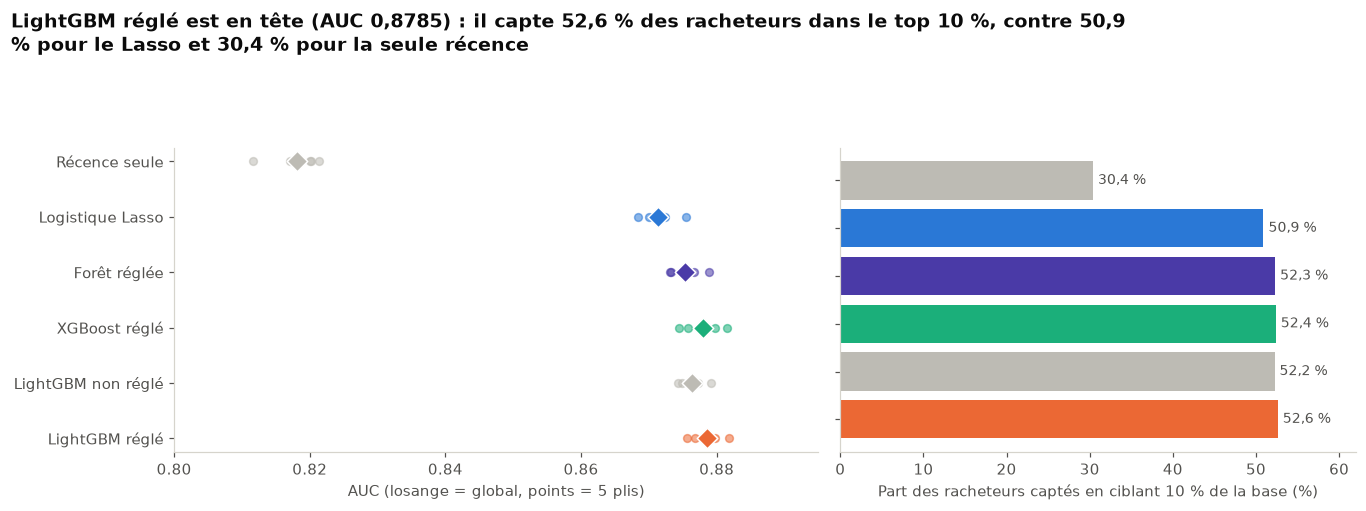

In [3]:
order = ['recency_rule', 'logreg_lasso', 'rf_tuned', 'xgb_tuned', 'lgbm_default', 'lgbm_tuned']
COL = {'recency_rule': c.GREY, 'logreg_lasso': c.BLUE, 'rf_tuned': c.PURPLE, 'xgb_tuned': c.GREEN, 'lgbm_default': c.GREY, 'lgbm_tuned': c.ACCENT}
NAME_SHORT = {'recency_rule': 'Récence seule', 'logreg_lasso': 'Logistique Lasso', 'rf_tuned': 'Forêt réglée', 'xgb_tuned': 'XGBoost réglé',
              'lgbm_default': 'LightGBM non réglé', 'lgbm_tuned': 'LightGBM réglé'}
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axs[0]
for i, n in enumerate(order[::-1]):
    ax.scatter(fold_auc[n], [i] * c.N_FOLDS, s=26, color=COL[n], alpha=.55, zorder=2)
    ax.scatter(rep[n]['auc'], i, s=90, marker='D', color=COL[n], edgecolor='white', zorder=3)
ax.set_yticks(range(len(order))); ax.set_yticklabels([NAME_SHORT[n] for n in order[::-1]])
ax.set_xlabel('AUC (losange = global, points = 5 plis)'); ax.set_xlim(0.80, 0.895)
ax = axs[1]
vals = [rep[n]['recall_top10'] * 100 for n in order[::-1]]
ax.barh(range(len(order)), vals, color=[COL[n] for n in order[::-1]])
for i, v in enumerate(vals):
    ax.text(v + .6, i, fr(v, 1) + ' %', va='center', fontsize=9, color=c.INK2)
ax.set_yticks(range(len(order))); ax.set_yticklabels([]); ax.set_xlim(0, 62)
ax.set_xlabel('Part des racheteurs captés en ciblant 10 % de la base (%)')
done(fig, '06_choix_modele', f"LightGBM réglé est en tête (AUC {a4(rep['lgbm_tuned']['auc'])}) : il capte {pc(rep['lgbm_tuned']['recall_top10'])} des racheteurs dans le top 10 %, contre {pc(rep['logreg_lasso']['recall_top10'])} pour le Lasso et {pc(rep['recency_rule']['recall_top10'])} pour la seule récence")

In [4]:
BEST, REF_INTERP = 'lgbm_tuned', 'logreg_lasso'
second = max((n for n in CANDS if n not in (BEST, 'lgbm_no_profile')), key=lambda n: rep[n]['auc'])
md(f'''
**Décision : `{BEST}` (LightGBM réglé) est le modèle final ; `{REF_INTERP}` reste la référence interprétable.**

- **Performance.** `{BEST}` a la meilleure AUC hors-échantillon ({a4(rep[BEST]['auc'])}), le meilleur lift dans le top 10 % ({fr(rep[BEST]['lift_top10'], 2)}) et un log-loss parmi les plus bas ({a4(rep[BEST]['logloss'])}). Il gagne contre le Lasso dans {d_lasso[2]} plis sur 5 ({sg(d_lasso[0])} d'AUC en moyenne, bien au-delà de l'écart-type entre plis de {a4(rep[BEST]['auc_fold_std'])}).
- **Ce que l'écart ne prouve pas.** Contre `xgb_tuned` ({sg(d_xgb[0])}, {d_xgb[2]} plis sur 5) ou `lgbm_no_profile` ({sg(d_np[0])}), la différence est dans le bruit : le choix de LightGBM n'est pas une victoire nette sur XGBoost. Il se justifie aussi par le temps d'entraînement ({fr(ref.loc[BEST, 'fit_seconds'], 1)} s par pli contre {fr(ref.loc['rf_tuned', 'fit_seconds'], 1)} s pour la forêt) et par `TreeExplainer`, qui calcule les valeurs SHAP exactes pour les arbres.
- **Le prix de l'interprétabilité.** Passer du Lasso (44 coefficients non nuls, lisible en odds ratios) au boosting coûte de l'explicabilité native et rapporte {sg(d_lasso[0])} d'AUC et {fr((rep[BEST]['lift_top10'] - rep[REF_INTERP]['lift_top10']), 2)} point de lift. Pour un seul e-mail promo au top 10 %, ce gain compte ; pour expliquer les leviers à la direction, on garde le Lasso à côté (section 4).
- **Variante sans profil d'identité.** `lgbm_no_profile` (sans civilité, e-mail, département) perd {fr(abs(rep[BEST]['auc'] - rep['lgbm_no_profile']['auc']) * 1e4, 1)} points d'AUC sur 10 000 ({a4(rep['lgbm_no_profile']['auc'])}) : le profil d'identité apporte presque rien et soulève un risque de proxy d'âge ou de territoire (RGPD). **Le modèle final garde néanmoins les mêmes variables que le notebook 04** pour rester comparable ; retirer ce profil est une décision à prendre au déploiement (voir limites).
''')
best_json = {'modele_final': BEST, 'reference_interpretable': REF_INTERP,
             'auc_oof': rep[BEST]['auc'], 'auc_plis_moyenne': rep[BEST]['auc_fold_mean'], 'auc_plis_ecart_type': rep[BEST]['auc_fold_std'],
             'precision_top10': rep[BEST]['precision_top10'], 'rappel_top10': rep[BEST]['recall_top10'], 'lift_top10': rep[BEST]['lift_top10'],
             'logloss': rep[BEST]['logloss'], 'auc_reference_lasso': rep[REF_INTERP]['auc'], 'auc_recence': rep['recency_rule']['auc'],
             'predictions': 'final_lgbm', 'soumission': 'submissions/06_final.csv (non envoyée à Kaggle)'}


**Décision : `lgbm_tuned` (LightGBM réglé) est le modèle final ; `logreg_lasso` reste la référence interprétable.**

- **Performance.** `lgbm_tuned` a la meilleure AUC hors-échantillon (0,8785), le meilleur lift dans le top 10 % (5,26) et un log-loss parmi les plus bas (0,1897). Il gagne contre le Lasso dans 5 plis sur 5 (+0,0072 d'AUC en moyenne, bien au-delà de l'écart-type entre plis de 0,0022).
- **Ce que l'écart ne prouve pas.** Contre `xgb_tuned` (+0,0006, 5 plis sur 5) ou `lgbm_no_profile` (+0,0002), la différence est dans le bruit : le choix de LightGBM n'est pas une victoire nette sur XGBoost. Il se justifie aussi par le temps d'entraînement (2,2 s par pli contre 19,7 s pour la forêt) et par `TreeExplainer`, qui calcule les valeurs SHAP exactes pour les arbres.
- **Le prix de l'interprétabilité.** Passer du Lasso (44 coefficients non nuls, lisible en odds ratios) au boosting coûte de l'explicabilité native et rapporte +0,0072 d'AUC et 0,17 point de lift. Pour un seul e-mail promo au top 10 %, ce gain compte ; pour expliquer les leviers à la direction, on garde le Lasso à côté (section 4).
- **Variante sans profil d'identité.** `lgbm_no_profile` (sans civilité, e-mail, département) perd 2,3 points d'AUC sur 10 000 (0,8783) : le profil d'identité apporte presque rien et soulève un risque de proxy d'âge ou de territoire (RGPD). **Le modèle final garde néanmoins les mêmes variables que le notebook 04** pour rester comparable ; retirer ce profil est une décision à prendre au déploiement (voir limites).


## 2. Ré-entraînement du LightGBM et prédiction du test

On réentraîne **exactement** le modèle du notebook 04 : mêmes variables (170 colonnes après one-hot N − 1 des 6 qualitatives, jumeaux `log_*` retirés), mêmes hyperparamètres (`results/04_best_params.json`), mêmes 5 plis, mêmes graines. Deux objectifs : (i) vérifier que l'on retrouve l'AUC hors-échantillon du notebook 04 (garde-fou de reproductibilité), (ii) **conserver les 5 modèles de pli**, nécessaires à SHAP. La prédiction du test est la moyenne des scores des 5 modèles de pli (aucun ré-ajustement sur tout le train).

*Lien avec le cours : one-hot encoding à N − 1 indicatrices (slide 87) ; validation croisée (slide 69).*

In [5]:
base_cols = [k for k in Xtr.columns if not k.startswith('log_')]
cat_cols = [k for k in base_cols if not pd.api.types.is_numeric_dtype(Xtr[k])]
levels = {k: sorted(Xtr[k].unique()) for k in cat_cols}
assert all(set(Xte[k].unique()) <= set(levels[k]) for k in cat_cols), 'modalité du test absente du train'


def encode(X, cols):
    # one-hot N-1 des qualitatives (1er niveau = référence), colonnes float32 : identique au notebook 04
    parts = []
    for k in cols:
        if k in cat_cols:
            parts.append(pd.DataFrame({f'{k}__{re.sub(r"[^0-9A-Za-z]+", "_", str(l))}': (X[k].to_numpy() == l).astype('float32')
                                       for l in levels[k][1:]}, index=X.index))
        else:
            parts.append(X[[k]].astype('float32'))
    return pd.concat(parts, axis=1)


Z_tr, Z_te = encode(Xtr, base_cols), encode(Xte, base_cols)
ENC_COLS = list(Z_tr.columns)
OWNER = {}
for k in base_cols:
    for e in (encode(Xtr.iloc[:2], [k]).columns):
        OWNER[e] = k
A_tr, A_te = Z_tr.to_numpy(), Z_te.to_numpy()

P = json.load(open(c.RES / '04_best_params.json'))['lgbm_tuned']
LGB_BASE = dict(random_state=c.SEED, n_jobs=N_JOBS, verbose=-1, force_row_wise=True)


def fit_cv(cols_idx=None, params=P):
    # un modèle par pli ; prédictions hors-échantillon ; test = moyenne des 5 modèles de pli
    A, B = (A_tr, A_te) if cols_idx is None else (A_tr[:, cols_idx], A_te[:, cols_idx])
    oof, te, models, secs = np.zeros(len(A)), np.zeros(len(B)), [], []
    for k in range(c.N_FOLDS):
        tr, va = fold != k, fold == k
        t0 = time.time(); m = lgb.LGBMClassifier(**params, **LGB_BASE).fit(A[tr], yv[tr]); secs.append(time.time() - t0)
        oof[va] = m.predict_proba(A[va])[:, 1]; te += m.predict_proba(B)[:, 1] / c.N_FOLDS
        models.append(m)
    return pd.Series(oof, index=Xtr.index), pd.Series(te, index=Xte.index), models, float(np.mean(secs))


oof_s, te_s, MODELS, SECS = fit_cv()
rep_f = c.cv_report(y, oof_s, folds)
fold_auc_f = np.array([roc_auc_score(yv[fold == k], oof_s.to_numpy()[fold == k]) for k in range(c.N_FOLDS)])
gap_auc = abs(rep_f['auc'] - rep['lgbm_tuned']['auc'])
gap_oof = float(np.abs(oof_s.to_numpy() - OOF['lgbm_tuned'].to_numpy()).max())
gap_te = float(np.abs(te_s.reindex(PRED['lgbm_tuned'][1].index).to_numpy() - PRED['lgbm_tuned'][1].to_numpy()).max())

c.save_predictions('final_lgbm', oof_s, te_s)
path_sub = c.write_submission(te_s, '06_final')
sub = pd.read_csv(path_sub)
assert list(sub.columns) == ['ID', 'Expected'] and len(sub) == len(Xte) and sub['Expected'].between(0, 1).all() and sub['ID'].is_unique

md(f'''
- Matrice d'entrée : **{nf(A_tr.shape[0])} clients × {A_tr.shape[1]} colonnes** ; {SECS:.1f} s par pli.
- **AUC hors-échantillon : {a4(rep_f['auc'])}** (notebook 04 : {a4(rep['lgbm_tuned']['auc'])}, écart {gap_auc:.1e}) ; écart maximal des scores hors-échantillon avec ceux du notebook 04 : {gap_oof:.1e} ; sur le test : {gap_te:.1e}.
- Prédictions enregistrées sous `final_lgbm` ; fichier `submissions/06_final.csv` écrit ({nf(len(sub))} lignes, colonnes `ID, Expected`, scores entre {sub['Expected'].min():.4f} et {sub['Expected'].max():.3f}). **Rien n'a été envoyé à Kaggle.**
- Score moyen sur le test : {pc(te_s.mean(), 2)}, contre {pc(oof_s.mean(), 2)} hors-échantillon sur le train et {pc(BASE_RATE, 2)} de rachat réel (test tiré au hasard dans la même population : aucune dérive attendue).
''')
assert gap_auc < 1e-6, 'le ré-entraînement ne retrouve pas l\'AUC du notebook 04'
KEY.update({'auc_oof': rep_f['auc'], 'gap_auc_vs_04': gap_auc, 'test_mean_score': float(te_s.mean()), 'oof_mean_score': float(oof_s.mean())})


- Matrice d'entrée : **160 424 clients × 170 colonnes** ; 1.6 s par pli.
- **AUC hors-échantillon : 0,8785** (notebook 04 : 0,8785, écart 0.0e+00) ; écart maximal des scores hors-échantillon avec ceux du notebook 04 : 0.0e+00 ; sur le test : 0.0e+00.
- Prédictions enregistrées sous `final_lgbm` ; fichier `submissions/06_final.csv` écrit (40 106 lignes, colonnes `ID, Expected`, scores entre 0.0019 et 0.886). **Rien n'a été envoyé à Kaggle.**
- Score moyen sur le test : 7,75 %, contre 7,69 % hors-échantillon sur le train et 7,72 % de rachat réel (test tiré au hasard dans la même population : aucune dérive attendue).


## 3. Évaluation business : ce que rapporte le score quand on cible 10 % de la base

L'e-mail promo ne peut partir qu'à **10 % de la base** (16 042 clients du train). Quatre lectures complémentaires : la courbe ROC (qualité du classement dans son ensemble), les courbes de **gain** (part des racheteurs captés quand on cible les x % les mieux classés) et de **lift** (combien de fois mieux qu'un tirage au hasard), puis le tableau par **décile**. *Lien avec le cours : AUC, précision, rappel, matrice de confusion (slides 66-73) ; ciblage (slide 74).*

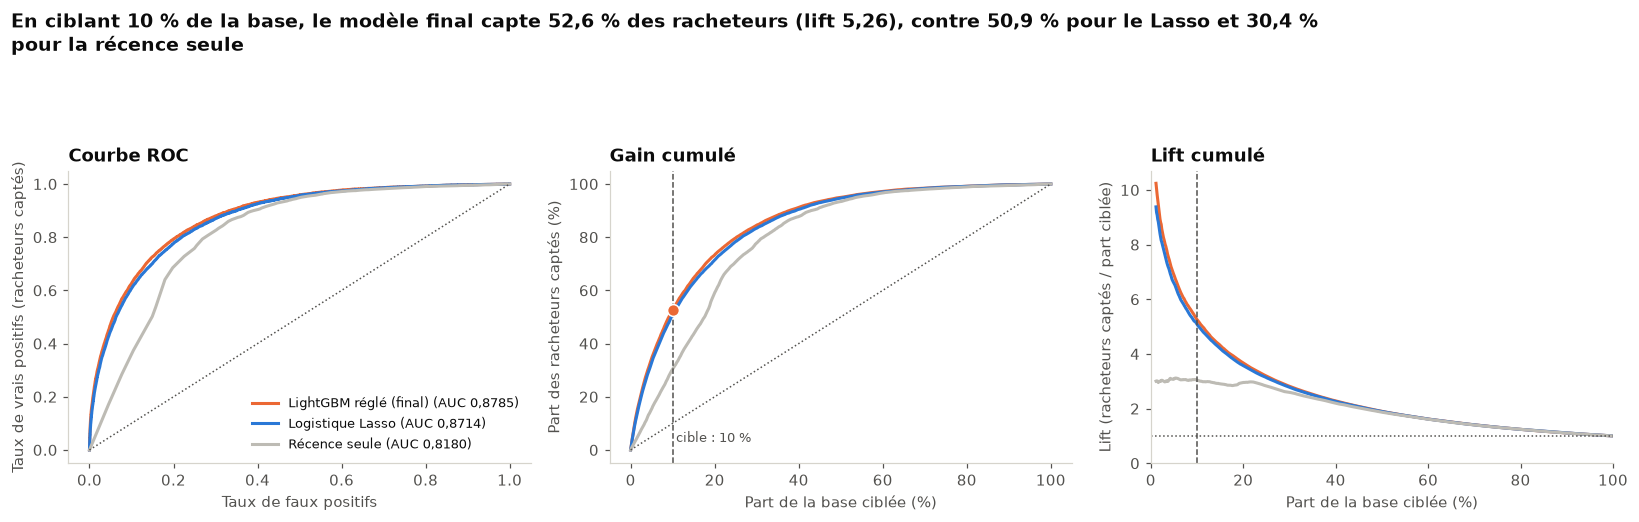

In [6]:
n = N_TR
x_all = np.arange(1, n + 1) / n


def gain_curve(score):
    o = np.argsort(-np.asarray(score), kind='stable')
    return np.cumsum(yv[o]) / yv.sum()


CURVES = {'final': ('LightGBM réglé (final)', oof_s, c.ACCENT, '-'), 'lasso': ('Logistique Lasso', OOF['logreg_lasso'], c.BLUE, '-'),
          'rec': ('Récence seule', OOF['recency_rule'], c.GREY, '-')}
G = {k: gain_curve(v[1]) for k, v in CURVES.items()}
thin = np.unique(np.r_[np.arange(0, n, 200), n - 1])
fig, axs = plt.subplots(1, 3, figsize=(15, 4.7))
ax = axs[0]
for k, (lbl, s, col, ls) in CURVES.items():
    fpr, tpr, _ = roc_curve(yv, s.to_numpy())
    ax.plot(fpr, tpr, color=col, lw=2, label=f"{lbl} (AUC {a4(roc_auc_score(yv, s.to_numpy()))})")
ax.plot([0, 1], [0, 1], color=c.INK2, lw=1, ls=':')
ax.set_xlabel('Taux de faux positifs'); ax.set_ylabel('Taux de vrais positifs (racheteurs captés)'); ax.legend(frameon=False, fontsize=8.5, loc='lower right'); ax.set_title('Courbe ROC', loc='left')
ax = axs[1]
for k, (lbl, s, col, ls) in CURVES.items():
    ax.plot(x_all[thin] * 100, G[k][thin] * 100, color=col, lw=2, label=lbl)
ax.plot([0, 100], [0, 100], color=c.INK2, lw=1, ls=':')
ax.axvline(10, color=c.INK2, lw=1, ls='--'); ax.text(10.8, 3, 'cible : 10 %', fontsize=8.5, color=c.INK2)
ax.scatter([10], [G['final'][int(round(.1 * n)) - 1] * 100], s=60, color=c.ACCENT, zorder=3, edgecolor='white')
ax.set_xlabel('Part de la base ciblée (%)'); ax.set_ylabel('Part des racheteurs captés (%)'); ax.set_title('Gain cumulé', loc='left')
ax = axs[2]
for k, (lbl, s, col, ls) in CURVES.items():
    m_ = x_all[thin] >= 0.01
    ax.plot(x_all[thin][m_] * 100, (G[k][thin] / x_all[thin])[m_], color=col, lw=2, label=lbl)
ax.axhline(1, color=c.INK2, lw=1, ls=':'); ax.axvline(10, color=c.INK2, lw=1, ls='--')
ax.set_xlabel('Part de la base ciblée (%)'); ax.set_ylabel('Lift (racheteurs captés / part ciblée)'); ax.set_title('Lift cumulé', loc='left')
ax.set_xlim(0, 100); ax.set_ylim(0, None)
k10 = int(round(c.TOP_FRAC * n))
done(fig, '06_roc_gain_lift', f"En ciblant 10 % de la base, le modèle final capte {pc(G['final'][k10 - 1])} des racheteurs (lift {fr(G['final'][k10 - 1] / .1, 2)}), contre {pc(G['lasso'][k10 - 1])} pour le Lasso et {pc(G['rec'][k10 - 1])} pour la récence seule")

In [7]:
# --- tableau par décile (décile 1 = les 10 % de clients les mieux classés) ---
rk = oof_s.rank(method='first', ascending=False)
dec = np.ceil(rk.to_numpy() / n * 10).astype(int)
dt = pd.DataFrame({'dec': dec, 'y': yv, 'p': oof_s.to_numpy()}).groupby('dec').agg(clients=('y', 'size'), racheteurs=('y', 'sum'), taux_rachat=('y', 'mean'), score_moyen=('p', 'mean'))
dt['lift'] = dt['taux_rachat'] / BASE_RATE
dt['part_racheteurs'] = dt['racheteurs'] / yv.sum()
dt['part_cumulee'] = dt['part_racheteurs'].cumsum()
dt.index.name = 'decile'
c.save_result('06_deciles', dt)
display(dt.style.format({'clients': '{:,.0f}', 'racheteurs': '{:,.0f}', 'taux_rachat': '{:.1%}', 'score_moyen': '{:.1%}', 'lift': '{:.2f}', 'part_racheteurs': '{:.1%}', 'part_cumulee': '{:.1%}'}))

# --- précision / rappel / lift selon la taille de la cible, pour trois modèles ---
tk = []
for fr_ in (0.05, 0.10, 0.20, 0.30):
    for k, (lbl, s, col, ls) in CURVES.items():
        m = c.topk_metrics(yv, s.to_numpy(), fr_)
        tk.append({'cible': f'{int(fr_ * 100)} %', 'modèle': lbl, 'clients ciblés': m['k'], 'précision': m['precision'], 'rappel': m['recall'], 'lift': m['lift']})
tk = pd.DataFrame(tk)
c.save_result('06_topk_metrics', tk.set_index(['cible', 'modèle']))
display(tk[tk['cible'] == '10 %'].set_index('modèle').drop(columns='cible').style.format({'précision': '{:.1%}', 'rappel': '{:.1%}', 'lift': '{:.2f}', 'clients ciblés': '{:,.0f}'}))

# --- matrice de confusion au seuil « top 10 % » ---
top_mask = rk.to_numpy() <= k10
TP, FP = int(yv[top_mask].sum()), int((1 - yv[top_mask]).sum())
FN, TN = int(yv[~top_mask].sum()), int((1 - yv[~top_mask]).sum())
thr = float(oof_s.to_numpy()[top_mask].min())
mail = Xtr['has_email'].to_numpy() == 1
share_top_mail = mail[top_mask].mean()
prec_mail = yv[top_mask & mail].mean(); prec_nomail = yv[top_mask & ~mail].mean()
md(f'''
**Lecture.** Les 10 % de clients les mieux classés ({nf(k10)} clients, score ≥ {pc(thr, 1)}) rachètent à **{pc(dt.loc[1, 'taux_rachat'])}**, soit **{fr(dt.loc[1, 'lift'], 2)} fois** le taux moyen ({pc(BASE_RATE)}) : on y trouve **{pc(dt.loc[1, 'part_racheteurs'])}** de tous les racheteurs. À l'autre bout, les 5 derniers déciles ne contiennent que {pc(1 - dt.loc[:5, 'part_cumulee'].iloc[-1])} des racheteurs.
Au seuil du top 10 % : {nf(TP)} vrais positifs, {nf(FP)} faux positifs, {nf(FN)} racheteurs manqués, {nf(TN)} vrais négatifs. **Environ {fr(100 * (1 - TP / k10), 0)} clients ciblés sur 100 ne rachèteront pas** : c'est la précision ({pc(TP / k10)}), plus que le rappel, qui limite l'efficacité d'un ciblage au top 10 %.
Contrainte opérationnelle à garder en tête pour le notebook 07 : **{pc(1 - share_top_mail)} du top 10 % n'a pas d'e-mail** et est injoignable par ce canal (précision {pc(prec_nomail)} chez eux contre {pc(prec_mail)} chez les joignables : le modèle ne s'appuie pas sur l'e-mail).
''')
KEY.update({'top10_precision': TP / k10, 'top10_recall': TP / yv.sum(), 'top10_lift': TP / k10 / BASE_RATE, 'top10_threshold_score': thr,
            'top10_TP': TP, 'top10_FP': FP, 'top10_FN': FN, 'top10_TN': TN, 'top10_share_no_email': float(1 - share_top_mail),
            'top10_precision_email': float(prec_mail), 'top10_precision_no_email': float(prec_nomail)})

,clients,racheteurs,taux_rachat,score_moyen,lift,part_racheteurs,part_cumulee
decile,,,,,,,
1,"16,042","6,521",40.6%,40.6%,5.26,52.6%,52.6%
2,"16,042","2,568",16.0%,15.8%,2.07,20.7%,73.3%
3,"16,043","1,387",8.6%,8.6%,1.12,11.2%,84.5%
4,"16,042",824,5.1%,5.1%,0.66,6.6%,91.2%
5,"16,043",469,2.9%,3.0%,0.38,3.8%,95.0%
6,"16,042",277,1.7%,1.6%,0.22,2.2%,97.2%
7,"16,042",149,0.9%,0.9%,0.12,1.2%,98.4%
8,"16,043",93,0.6%,0.6%,0.08,0.8%,99.2%
9,"16,042",62,0.4%,0.4%,0.05,0.5%,99.7%


,clients ciblés,précision,rappel,lift
modèle,,,,
LightGBM réglé (final),"16,042",40.6%,52.6%,5.26
Logistique Lasso,"16,042",39.3%,50.9%,5.09
Récence seule,"16,042",23.5%,30.4%,3.04



**Lecture.** Les 10 % de clients les mieux classés (16 042 clients, score ≥ 22,2 %) rachètent à **40,6 %**, soit **5,26 fois** le taux moyen (7,7 %) : on y trouve **52,6 %** de tous les racheteurs. À l'autre bout, les 5 derniers déciles ne contiennent que 5,0 % des racheteurs.
Au seuil du top 10 % : 6 521 vrais positifs, 9 521 faux positifs, 5 871 racheteurs manqués, 138 511 vrais négatifs. **Environ 59 clients ciblés sur 100 ne rachèteront pas** : c'est la précision (40,6 %), plus que le rappel, qui limite l'efficacité d'un ciblage au top 10 %.
Contrainte opérationnelle à garder en tête pour le notebook 07 : **35,9 % du top 10 % n'a pas d'e-mail** et est injoignable par ce canal (précision 41,4 % chez eux contre 40,3 % chez les joignables : le modèle ne s'appuie pas sur l'e-mail).


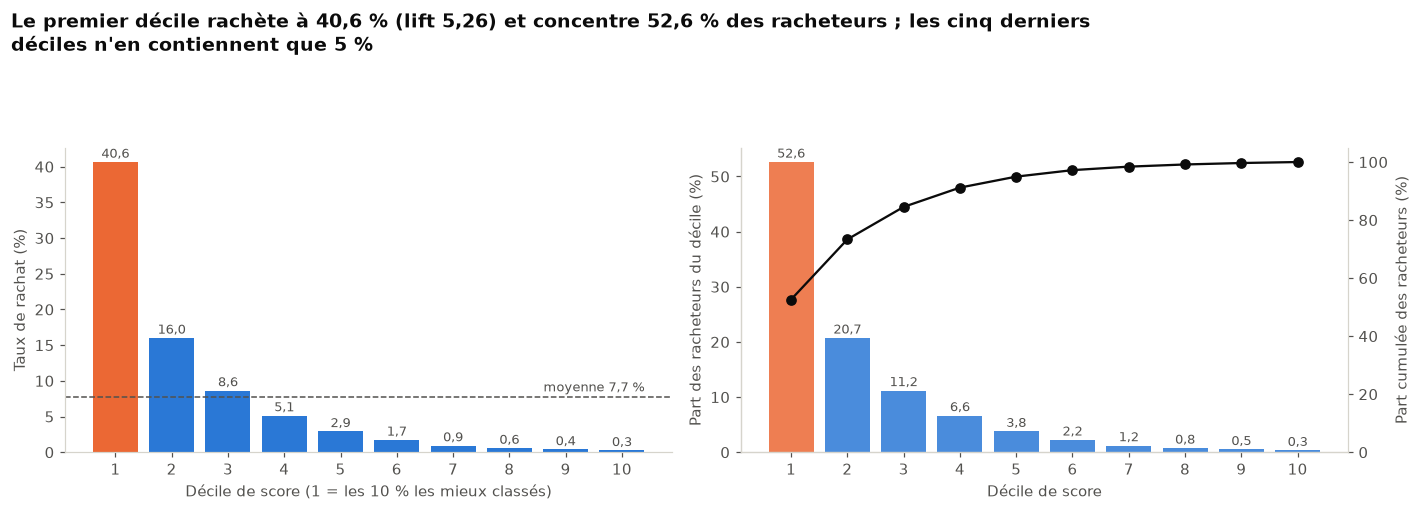

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
ax.bar(dt.index, dt['taux_rachat'] * 100, color=[c.ACCENT if d == 1 else c.BLUE for d in dt.index])
ax.axhline(BASE_RATE * 100, color=c.INK2, lw=1, ls='--'); ax.text(10.4, BASE_RATE * 100 + .8, f'moyenne {pc(BASE_RATE)}', ha='right', fontsize=8.5, color=c.INK2)
for d, v in dt['taux_rachat'].items():
    ax.text(d, v * 100 + .6, fr(v * 100, 1), ha='center', fontsize=8.5, color=c.INK2)
ax.set_xticks(range(1, 11)); ax.set_xlabel('Décile de score (1 = les 10 % les mieux classés)'); ax.set_ylabel('Taux de rachat (%)')
ax = axs[1]
ax.bar(dt.index, dt['part_racheteurs'] * 100, color=[c.ACCENT if d == 1 else c.BLUE for d in dt.index], alpha=.85)
ax2 = ax.twinx(); ax2.plot(dt.index, dt['part_cumulee'] * 100, color=c.INK, marker='o', lw=1.5); ax2.set_ylim(0, 105); ax2.spines['right'].set_visible(True); ax2.set_ylabel('Part cumulée des racheteurs (%)', color=c.INK2)
for d, v in dt['part_racheteurs'].items():
    ax.text(d, v * 100 + .8, fr(v * 100, 1), ha='center', fontsize=8.5, color=c.INK2)
ax.set_xticks(range(1, 11)); ax.set_xlabel('Décile de score'); ax.set_ylabel('Part des racheteurs du décile (%)')
done(fig, '06_deciles', f"Le premier décile rachète à {pc(dt.loc[1, 'taux_rachat'])} (lift {fr(dt.loc[1, 'lift'], 2)}) et concentre {pc(dt.loc[1, 'part_racheteurs'])} des racheteurs ; les cinq derniers déciles n'en contiennent que {pc(1 - dt.loc[:5, 'part_cumulee'].iloc[-1], 0)}")

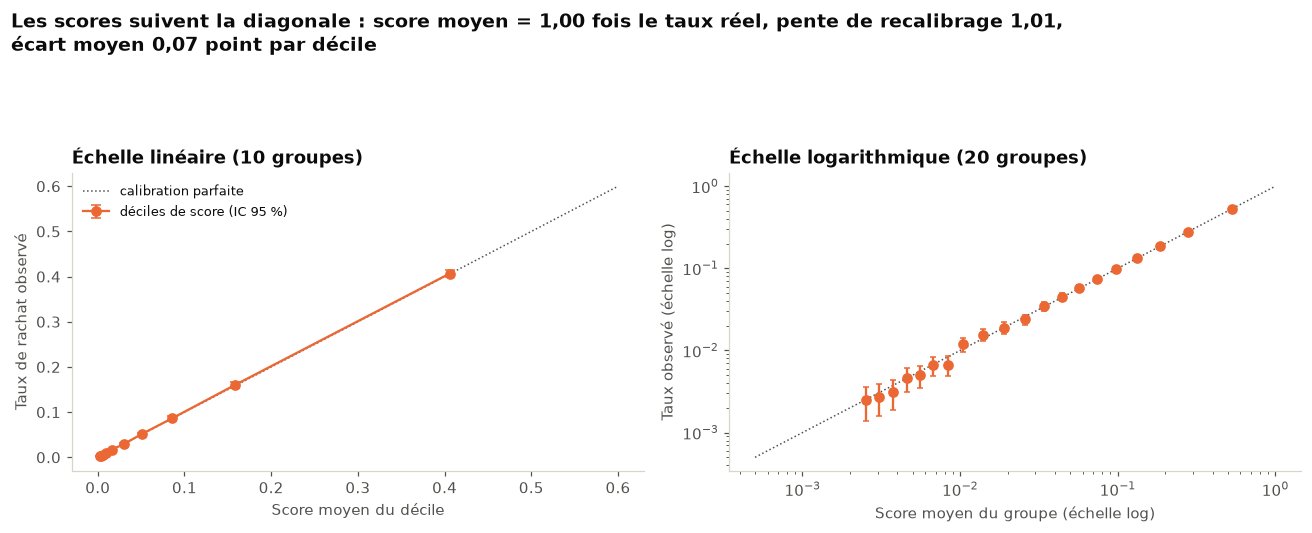


**Calibration.** Sur les prédictions hors-échantillon, le score moyen (7,69 %) est 0,996 fois le taux réel (7,72 %), la pente de recalibrage (régression logistique du rachat sur le logit du score) vaut 1,01 (1 = parfait) et l'écart moyen pondéré entre score et taux observé n'est que de 0,07 point par décile. Le modèle n'a pas été pondéré pour le déséquilibre (voir notebook 04 : la pondération dégrade ce point sans améliorer le classement).

**Pourquoi on ne s'y arrête pas.** Notre objectif est un **classement** : on cible les 10 % de scores les plus élevés, et la métrique Kaggle (AUC) est invariante à toute transformation croissante du score. Une probabilité précise n'a de sens que si on veut chiffrer un nombre de racheteurs attendus. Et même alors, **la cible est plus étroite que « acheter dans le mois »** (le taux de 7,7 % équivaut à environ 1,9 jour d'activité, cf. notebook 01) : « 22 % de probabilité » signifie « probabilité d'acheter en août 2020 dans les conditions de ce mois précis », pas un taux mensuel général. Pour les scénarios économiques (notebook 07), on s'appuiera sur les **taux observés par décile** du tableau ci-dessus, pas sur les probabilités brutes.


In [9]:
# --- calibration (diagramme de fiabilité) ---
def calib_table(p, yy, q):
    d = pd.DataFrame({'p': p, 'y': yy})
    d['b'] = pd.qcut(d['p'].rank(method='first'), q, labels=False)
    g = d.groupby('b').agg(score=('p', 'mean'), taux=('y', 'mean'), n=('y', 'size'))
    g['ic'] = 1.96 * np.sqrt(g['taux'] * (1 - g['taux']) / g['n'])
    return g


pp = np.clip(oof_s.to_numpy(), 1e-6, 1 - 1e-6)
slope = LogisticRegression(C=1e8, max_iter=300).fit(np.log(pp / (1 - pp)).reshape(-1, 1), yv).coef_[0, 0]
cal10, cal20 = calib_table(oof_s.to_numpy(), yv, 10), calib_table(oof_s.to_numpy(), yv, 20)
ece = float((np.abs(cal10['score'] - cal10['taux']) * cal10['n']).sum() / n)
ratio = float(oof_s.mean() / BASE_RATE)
c.save_result('06_calibration', cal20.rename_axis('quantile_score'))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axs[0]
ax.plot([0, .6], [0, .6], color=c.INK2, lw=1, ls=':', label='calibration parfaite')
ax.errorbar(cal10['score'], cal10['taux'], yerr=cal10['ic'], fmt='o-', color=c.ACCENT, lw=1.5, capsize=3, label='déciles de score (IC 95 %)')
ax.set_xlabel('Score moyen du décile'); ax.set_ylabel('Taux de rachat observé'); ax.legend(frameon=False, fontsize=8.5); ax.set_title('Échelle linéaire (10 groupes)', loc='left')
ax = axs[1]
ax.plot([5e-4, 1], [5e-4, 1], color=c.INK2, lw=1, ls=':')
ax.errorbar(cal20['score'], cal20['taux'].clip(lower=1e-4), yerr=cal20['ic'], fmt='o', color=c.ACCENT, capsize=2)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Score moyen du groupe (échelle log)'); ax.set_ylabel('Taux observé (échelle log)'); ax.set_title('Échelle logarithmique (20 groupes)', loc='left')
done(fig, '06_calibration', f"Les scores suivent la diagonale : score moyen = {fr(ratio, 2)} fois le taux réel, pente de recalibrage {fr(slope, 2)}, écart moyen {fr(ece * 100, 2)} point par décile")
md(f'''
**Calibration.** Sur les prédictions hors-échantillon, le score moyen ({pc(oof_s.mean(), 2)}) est {fr(ratio, 3)} fois le taux réel ({pc(BASE_RATE, 2)}), la pente de recalibrage (régression logistique du rachat sur le logit du score) vaut {fr(slope, 2)} (1 = parfait) et l'écart moyen pondéré entre score et taux observé n'est que de {fr(ece * 100, 2)} point par décile. Le modèle n'a pas été pondéré pour le déséquilibre (voir notebook 04 : la pondération dégrade ce point sans améliorer le classement).

**Pourquoi on ne s'y arrête pas.** Notre objectif est un **classement** : on cible les 10 % de scores les plus élevés, et la métrique Kaggle (AUC) est invariante à toute transformation croissante du score. Une probabilité précise n'a de sens que si on veut chiffrer un nombre de racheteurs attendus. Et même alors, **la cible est plus étroite que « acheter dans le mois »** (le taux de {pc(BASE_RATE)} équivaut à environ 1,9 jour d'activité, cf. notebook 01) : « {pc(thr, 0)} de probabilité » signifie « probabilité d'acheter en août 2020 dans les conditions de ce mois précis », pas un taux mensuel général. Pour les scénarios économiques (notebook 07), on s'appuiera sur les **taux observés par décile** du tableau ci-dessus, pas sur les probabilités brutes.
''')
KEY.update({'calib_mean_ratio': ratio, 'calib_slope': float(slope), 'calib_ece_deciles': ece})

## 4. Interprétation par SHAP

Une valeur SHAP décompose le score d'**un client** en contributions, une par variable, exprimées en **log-cote** (la cote, ou odds, est p / (1 − p) ; une contribution de +0,7 multiplie la cote par environ 2). Somme des contributions + valeur de base = score brut du modèle : l'explication est exacte, pas approchée. *Lien avec le cours : SHAP comme outil d'interprétabilité des modèles de boosting (slide 64) ; compromis performance / interprétabilité (slides 66-73).*

**Protocole.** 2 000 clients tirés au hasard dans chaque pli de validation (**10 000 clients** en tout), expliqués par le modèle du pli qui ne les a pas vus à l'entraînement : les explications portent donc sur des clients « nouveaux » pour le modèle. Les indicatrices du one-hot sont additionnées par variable d'origine pour les classements.

In [10]:
rs = np.random.RandomState(c.SEED)
IDX, SV, BASE = [], [], []
for k in range(c.N_FOLDS):
    idx = rs.choice(np.where(fold == k)[0], N_SHAP_PAR_PLI, replace=False)
    ex = shap.TreeExplainer(MODELS[k].booster_)
    v = ex.shap_values(A_tr[idx])
    v = v[1] if isinstance(v, list) else v
    SV.append(v); IDX.append(idx); BASE.append(np.full(len(idx), float(np.ravel(ex.expected_value)[-1])))
IDX = np.concatenate(IDX); SV = np.vstack(SV); BASE = np.concatenate(BASE)
assert len(IDX) <= 10_000
S = pd.DataFrame(SV, columns=ENC_COLS, index=Xtr.index[IDX])
Zs = Z_tr.iloc[IDX]
S_own = S.T.groupby(lambda e: OWNER[e]).sum().T                      # contributions agrégées par variable d'origine
raw_logit = BASE + SV.sum(axis=1)
sc = oof_s.iloc[IDX].to_numpy()
add_err = float(np.abs(raw_logit - np.log(sc / (1 - sc))).max())

imp = S_own.abs().mean().sort_values(ascending=False)
share_imp = imp / imp.sum()
dire = {}
for k in imp.index:
    if k in cat_cols:
        dire[k] = np.nan
    else:
        xv = Xtr.iloc[IDX][k].to_numpy(dtype=float); ok = ~np.isnan(xv)
        dire[k] = spearmanr(xv[ok], S_own[k].to_numpy()[ok])[0] if ok.sum() > 50 and np.nanstd(xv[ok]) > 0 else np.nan
dire = pd.Series(dire)
md(f'''
- {nf(len(IDX))} clients expliqués ({nf(yv[IDX].sum())} racheteurs, {pc(yv[IDX].mean())} contre {pc(BASE_RATE)} dans le train) ; valeur de base moyenne = {fr(BASE.mean(), 2)} en log-cote (probabilité {pc(1 / (1 + np.exp(-BASE.mean())))}).
- Contrôle d'additivité : écart maximal entre « base + somme des SHAP » et le logit du score hors-échantillon = **{add_err:.1e}**.
- Les 5 premières variables portent **{pc(share_imp.head(5).sum(), 0)}** de l'importance SHAP totale (moyenne des |SHAP|), les 10 premières {pc(share_imp.head(10).sum(), 0)}.
''')
assert add_err < 1e-4


- 10 000 clients expliqués (787 racheteurs, 7,9 % contre 7,7 % dans le train) ; valeur de base moyenne = -3,61 en log-cote (probabilité 2,6 %).
- Contrôle d'additivité : écart maximal entre « base + somme des SHAP » et le logit du score hors-échantillon = **1.2e-14**.
- Les 5 premières variables portent **44 %** de l'importance SHAP totale (moyenne des |SHAP|), les 10 premières 57 %.


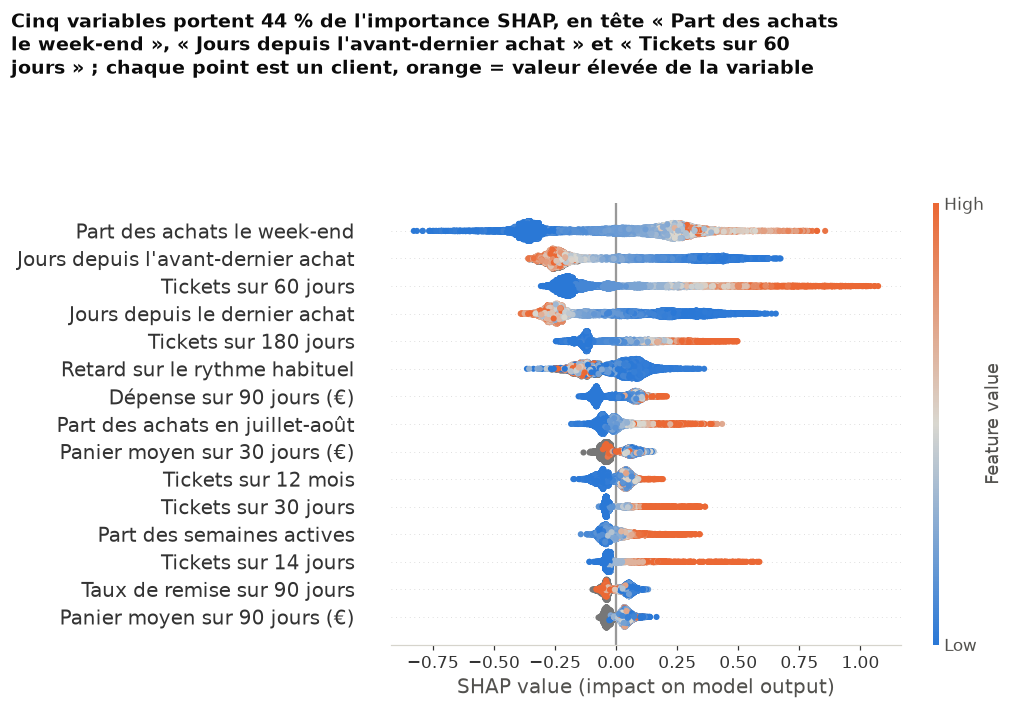

In [11]:
# --- résumé SHAP (beeswarm) sur les colonnes encodées ---
CMAP = LinearSegmentedColormap.from_list('bleu_orange', [c.BLUE, '#d9d7d0', c.ACCENT])
Zl = Zs.copy(); Zl.columns = [lab_enc(e) for e in Zl.columns]
plt.figure(figsize=(9.5, 6.4))
shap.summary_plot(SV, Zl, max_display=15, show=False, cmap=CMAP, plot_size=None)
fig = plt.gcf()
done(fig, '06_shap_resume', f"Cinq variables portent {pc(share_imp.head(5).sum(), 0)} de l'importance SHAP, en tête « {lab(imp.index[0])} », « {lab(imp.index[1])} » et « {lab(imp.index[2])} » ; chaque point est un client, orange = valeur élevée de la variable")

,variable,part SHAP (%),sens SHAP (ρ),coef. Lasso (par σ),OR Lasso,OR ré-estimé,rang OR
share_weekend,Part des achats le week-end,10.5,+0.95,+0.57,1.76,1.79,1
recency_prev_days,Jours depuis l'avant-dernier achat,10.1,-0.95,-0.00,1.00,0.83,11
n_tickets_60,Tickets sur 60 jours,9.3,+0.94,+0.24,1.28,1.27,7
recency_days,Jours depuis le dernier achat,8.9,-0.93,-0.37,0.69,0.71,3
n_tickets_180,Tickets sur 180 jours,5.2,+0.90,+0.36,1.43,1.32,6
delay_ratio_mean,Retard sur le rythme habituel,3.6,-0.30,+0.03,1.03,1.23,8
spend_90,Dépense sur 90 jours (€),3.0,+0.92,+0.24,1.28,1.48,2
share_summer_months,Part des achats en juillet-août,2.2,+0.92,+0.23,1.26,1.33,5
basket_mean_30,Panier moyen sur 30 jours (€),2.1,-0.32,-0.03,0.97,0.98,37
n_tickets_all,Tickets sur 12 mois,2.0,+0.84,+0.17,1.18,1.04,29


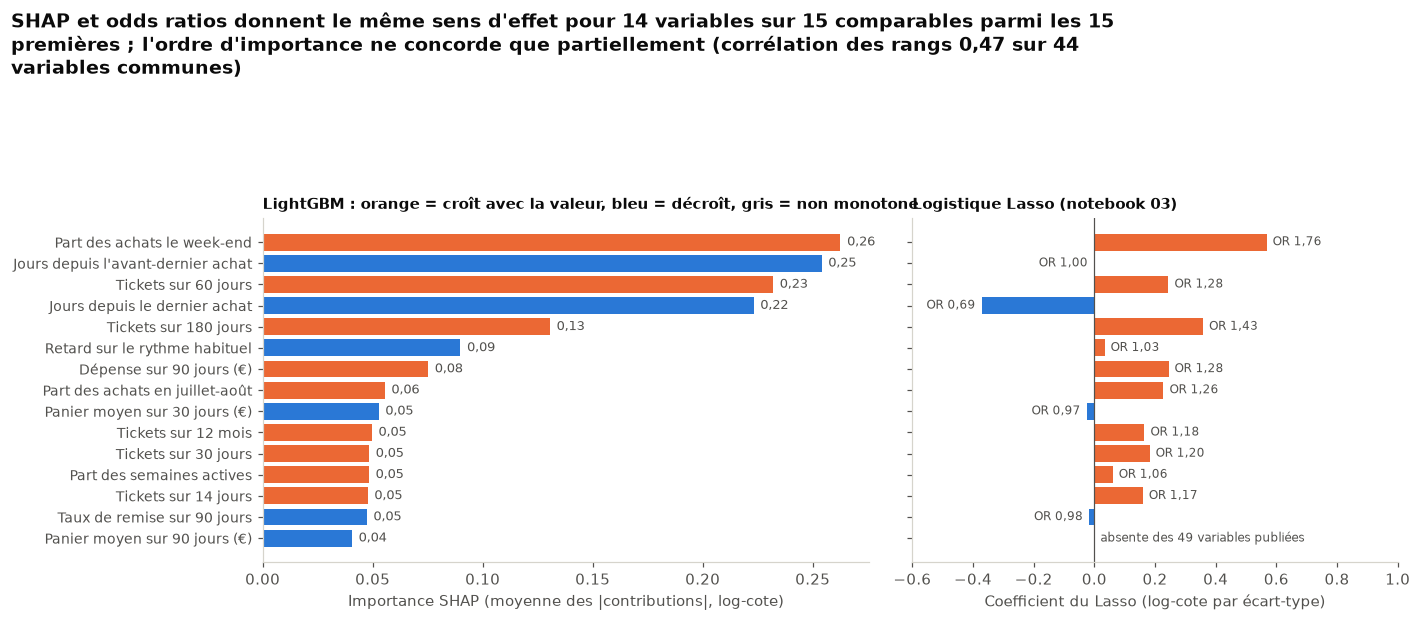


**Lecture croisée (SHAP × odds ratios).**
- **Même verdict de fond, ordre plus nuancé** (corrélation des rangs 0,47 : la logistique privilégie la dépense et les comptages, le boosting la récence et le week-end). Les deux modèles, de nature très différente, placent en tête les mêmes familles : le **rythme d'achat récent** (jours depuis le dernier achat, nombre de tickets sur 60 jours) et la **part d'achats le week-end** ; `Part des achats le week-end` est n° 1 en SHAP et n° 1 aux odds ratios (OR par écart-type : 1,76). Le fait que la variable domine **aussi dans le modèle linéaire** montre qu'il ne s'agit pas d'un artefact du boosting (voir section 6).
- **Mêmes sens.** Plus on a acheté récemment, plus on rachète ; plus on est fréquent, plus on rachète ; sens identiques sur 14 des 15 variables comparables du top 15.
- **Différences attendues.** (i) La logistique répartit l'effet entre des variables très corrélées (jusqu'à 0,92 entre comptages de tickets) : un coefficient Lasso peut être nul alors que SHAP l'exprime (ex. `recency_prev_days`, coefficient Lasso -0,002 contre rang SHAP 2). (ii) Les effets du boosting ne sont pas linéaires (section suivante) : un odds ratio par écart-type est une moyenne, SHAP montre la forme. (iii) Seules 49 variables sont publiées dans le tableau du notebook 03.


In [12]:
# --- comparaison avec les odds ratios du notebook 03 (Lasso) ---
OR = pd.read_csv(c.RES / '03_odds_ratios.csv')
OR['var'] = OR['variable'].str.replace(r'^log_', '', regex=True)
OR = OR.drop_duplicates('var').set_index('var')
cmp_ = pd.DataFrame({'libelle': [lab(k) for k in imp.index], 'shap_moyen_abs': imp.values, 'part_importance': share_imp.values, 'rang_shap': np.arange(1, len(imp) + 1),
                     'sens_shap_rho': dire.values}, index=imp.index)
cmp_['famille'] = pd.read_csv(c.RES / '02_feature_dictionary.csv').set_index('name')['group'].reindex(cmp_.index).values
cmp_['coef_lasso_par_ecart_type'] = OR['coef_lasso'].reindex(cmp_.index)
cmp_['or_lasso'] = OR['or_lasso'].reindex(cmp_.index)
cmp_['or_refit'] = OR['or_refit'].reindex(cmp_.index)
cmp_['rang_or'] = OR['poids'].rank(ascending=False).reindex(cmp_.index)
cmp_['meme_sens'] = np.where(cmp_['coef_lasso_par_ecart_type'].isna() | (cmp_['coef_lasso_par_ecart_type'] == 0) | cmp_['sens_shap_rho'].isna(), np.nan,
                             (np.sign(cmp_['coef_lasso_par_ecart_type']) == np.sign(cmp_['sens_shap_rho'])).astype(float))
c.save_result('06_shap_importance', cmp_)

top15 = cmp_.head(15)
ov = cmp_.dropna(subset=['coef_lasso_par_ecart_type'])
rho_rank = spearmanr(ov['shap_moyen_abs'], ov['coef_lasso_par_ecart_type'].abs())[0]
conc = ov.head(15).dropna(subset=['meme_sens'])
disp = top15[['libelle', 'part_importance', 'sens_shap_rho', 'coef_lasso_par_ecart_type', 'or_lasso', 'or_refit', 'rang_or']].copy()
disp['part_importance'] = (disp['part_importance'] * 100).round(1)
display(disp.rename(columns={'libelle': 'variable', 'part_importance': 'part SHAP (%)', 'sens_shap_rho': 'sens SHAP (ρ)', 'coef_lasso_par_ecart_type': 'coef. Lasso (par σ)', 'or_lasso': 'OR Lasso', 'or_refit': 'OR ré-estimé', 'rang_or': 'rang OR'}).style.format(
    {'part SHAP (%)': '{:.1f}', 'sens SHAP (ρ)': '{:+.2f}', 'coef. Lasso (par σ)': '{:+.2f}', 'OR Lasso': '{:.2f}', 'OR ré-estimé': '{:.2f}', 'rang OR': '{:.0f}'}, na_rep='-'))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={'width_ratios': [1.25, 1]})
t = top15[::-1]
colr = [c.GREY if np.isnan(v) or abs(v) < 0.1 else (c.ACCENT if v > 0 else c.BLUE) for v in t['sens_shap_rho']]
ax = axs[0]
ax.barh(range(len(t)), t['shap_moyen_abs'], color=colr)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t['libelle'], fontsize=9)
for i, v in enumerate(t['shap_moyen_abs']):
    ax.text(v + .003, i, fr(v, 2), va='center', fontsize=8.5, color=c.INK2)
ax.set_xlabel('Importance SHAP (moyenne des |contributions|, log-cote)')
ax.set_title('LightGBM : orange = croît avec la valeur, bleu = décroît, gris = non monotone', loc='left', fontsize=9.5)
ax = axs[1]
cf = t['coef_lasso_par_ecart_type']
ax.barh(range(len(t)), cf.fillna(0), color=[c.GREY if np.isnan(v) else (c.ACCENT if v > 0 else c.BLUE) for v in cf])
for i, (v, o) in enumerate(zip(cf, t['or_lasso'])):
    ax.text((v if not np.isnan(v) else 0) + (.02 if (np.isnan(v) or v >= 0) else -.02), i, 'absente des 49 variables publiées' if np.isnan(v) else f'OR {fr(o, 2)}', va='center', ha='left' if (np.isnan(v) or v >= 0) else 'right', fontsize=8, color=c.INK2)
ax.axvline(0, color=c.INK2, lw=.8); ax.set_yticks(range(len(t))); ax.set_yticklabels([]); ax.set_xlim(-.6, 1.0)
ax.set_xlabel('Coefficient du Lasso (log-cote par écart-type)'); ax.set_title('Logistique Lasso (notebook 03)', loc='left', fontsize=9.5)
done(fig, '06_shap_vs_odds_ratios', f"SHAP et odds ratios donnent le même sens d'effet pour {int(conc['meme_sens'].sum())} variables sur {len(conc)} comparables parmi les 15 premières ; l'ordre d'importance ne concorde que partiellement (corrélation des rangs {fr(rho_rank, 2)} sur {len(ov)} variables communes)")
md(f'''
**Lecture croisée (SHAP × odds ratios).**
- **Même verdict de fond, ordre plus nuancé** (corrélation des rangs {fr(rho_rank, 2)} : la logistique privilégie la dépense et les comptages, le boosting la récence et le week-end). Les deux modèles, de nature très différente, placent en tête les mêmes familles : le **rythme d'achat récent** (jours depuis le dernier achat, nombre de tickets sur 60 jours) et la **part d'achats le week-end** ; `{lab(imp.index[0])}` est n° {int(cmp_.loc[imp.index[0], 'rang_shap'])} en SHAP et n° {fr(cmp_.loc[imp.index[0], 'rang_or'], 0)} aux odds ratios (OR par écart-type : {fr(cmp_.loc[imp.index[0], 'or_lasso'], 2)}). Le fait que la variable domine **aussi dans le modèle linéaire** montre qu'il ne s'agit pas d'un artefact du boosting (voir section 6).
- **Mêmes sens.** Plus on a acheté récemment, plus on rachète ; plus on est fréquent, plus on rachète ; sens identiques sur {int(conc['meme_sens'].sum())} des {len(conc)} variables comparables du top 15.
- **Différences attendues.** (i) La logistique répartit l'effet entre des variables très corrélées (jusqu'à 0,92 entre comptages de tickets) : un coefficient Lasso peut être nul alors que SHAP l'exprime (ex. `recency_prev_days`, coefficient Lasso {fr(cmp_.loc['recency_prev_days', 'coef_lasso_par_ecart_type'], 3) if 'recency_prev_days' in cmp_.index and not np.isnan(cmp_.loc['recency_prev_days', 'coef_lasso_par_ecart_type']) else 'absent'} contre rang SHAP {int(cmp_.loc['recency_prev_days', 'rang_shap'])}). (ii) Les effets du boosting ne sont pas linéaires (section suivante) : un odds ratio par écart-type est une moyenne, SHAP montre la forme. (iii) Seules 49 variables sont publiées dans le tableau du notebook 03.
''')
KEY.update({'shap_top5': list(imp.index[:5]), 'shap_top5_share': float(share_imp.head(5).sum()), 'shap_or_rank_corr': float(rho_rank),
            'shap_or_same_sign': f"{int(conc['meme_sens'].sum())}/{len(conc)}", 'shap_additivity_err': add_err, 'shap_n': int(len(IDX))})

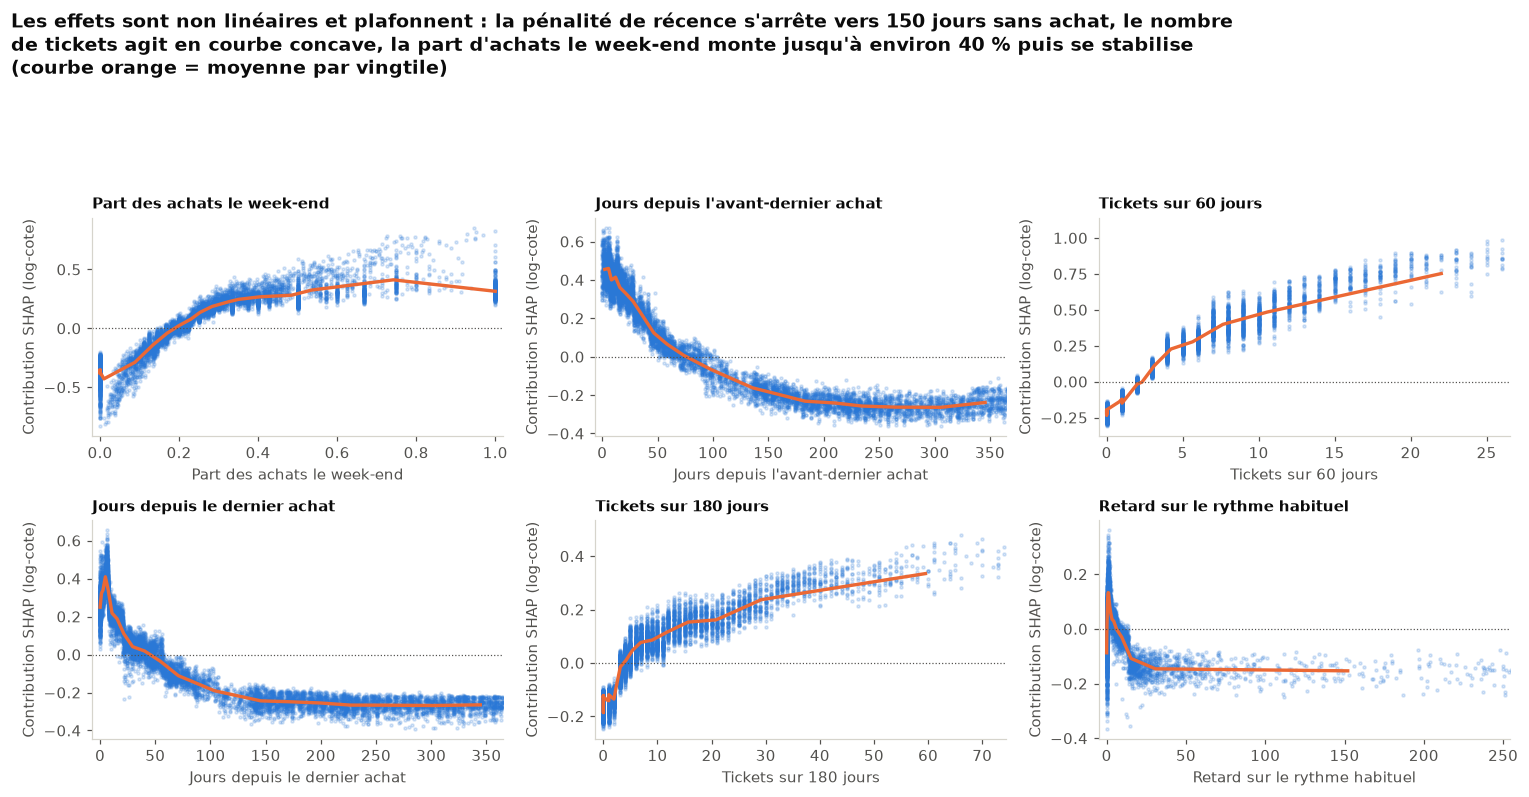


**Lecture marketing** (du bas au haut de la distribution : 2e et 19e vingtiles de la variable).
- **Part des achats le week-end** : (0,00 → 0,74) : la contribution passe de −0,38 à +0,41 en log-cote, soit un facteur **×2,22** sur la cote de rachat, toutes choses égales par ailleurs.
- **Jours depuis l'avant-dernier achat** : (5,64 → 305,69) : la contribution passe de +0,46 à −0,26 en log-cote, soit un facteur **×0,49** sur la cote de rachat, toutes choses égales par ailleurs.
- **Tickets sur 60 jours** : (0,00 → 10,56) : la contribution passe de −0,21 à +0,48 en log-cote, soit un facteur **×2,00** sur la cote de rachat, toutes choses égales par ailleurs.
- **Jours depuis le dernier achat** : (1,27 → 302,01) : la contribution passe de +0,32 à −0,27 en log-cote, soit un facteur **×0,55** sur la cote de rachat, toutes choses égales par ailleurs.
- **Tickets sur 180 jours** : (0,00 → 29,18) : la contribution passe de −0,19 à +0,24 en log-cote, soit un facteur **×1,53** sur la cote de rachat, toutes choses égales par ailleurs.
- **Retard sur le rythme habituel** : (0,05 → 30,73) : la contribution passe de −0,05 à −0,15 en log-cote, soit un facteur **×0,91** sur la cote de rachat, toutes choses égales par ailleurs.

Ces facteurs sont des **associations conditionnelles dans un modèle prédictif**, pas des effets causaux : « faire acheter plus souvent » n'est pas un levier démontré. Récence, fréquence et rythme se recouvrent largement : SHAP répartit leur effet commun entre elles, il faut donc les lire ensemble plutôt qu'isolément.


In [13]:
# --- dépendance sur les variables principales (numériques) ---
num_top = [k for k in imp.index if k not in cat_cols][:6]
fig, axs = plt.subplots(2, 3, figsize=(14, 7.2))
DEP = {}
for ax, k in zip(axs.ravel(), num_top):
    xv = Xtr.iloc[IDX][k].to_numpy(dtype=float); sv = S_own[k].to_numpy(); ok = ~np.isnan(xv)
    lo, hi = np.nanpercentile(xv, [1, 99])
    ax.scatter(xv[ok], sv[ok], s=4, alpha=.18, color=c.BLUE, rasterized=True)
    b = pd.qcut(pd.Series(xv[ok]).rank(method='first'), 20, labels=False)
    g = pd.DataFrame({'x': xv[ok], 's': sv[ok], 'b': b.to_numpy()}).groupby('b').mean()
    ax.plot(g['x'], g['s'], color=c.ACCENT, lw=2.2)
    ax.axhline(0, color=c.INK2, lw=.8, ls=':')
    ax.set_xlim(lo - .02 * (hi - lo), hi + .02 * (hi - lo)); ax.set_xlabel(lab(k)); ax.set_ylabel('Contribution SHAP (log-cote)')
    ax.set_title(f'{lab(k)}', loc='left', fontsize=10)
    DEP[k] = {'rho': float(dire[k]), 'shap_bas_decile': float(g['s'].iloc[1]), 'shap_haut_decile': float(g['s'].iloc[-2]),
              'x_bas': float(g['x'].iloc[1]), 'x_haut': float(g['x'].iloc[-2])}
sw = DEP.get('share_weekend')
done(fig, '06_shap_dependance', "Les effets sont non linéaires et plafonnent : la pénalité de récence s'arrête vers 150 jours sans achat, le nombre de tickets agit en courbe concave, la part d'achats le week-end monte jusqu'à environ 40 % puis se stabilise (courbe orange = moyenne par vingtile)")
c.save_result('06_shap_dependance', pd.DataFrame(DEP).T)
rec = DEP['recency_days'] if 'recency_days' in DEP else None
md(f'''
**Lecture marketing** (du bas au haut de la distribution : 2e et 19e vingtiles de la variable).
''' + '\n'.join(
    f"- **{lab(k)}** : ({fr(d['x_bas'], 2)} → {fr(d['x_haut'], 2)}) : la contribution passe de {sg(d['shap_bas_decile'], 2)} à {sg(d['shap_haut_decile'], 2)} en log-cote, soit un facteur **×{fr(np.exp(d['shap_haut_decile'] - d['shap_bas_decile']), 2)}** sur la cote de rachat, toutes choses égales par ailleurs."
    for k, d in DEP.items()) + '''

Ces facteurs sont des **associations conditionnelles dans un modèle prédictif**, pas des effets causaux : « faire acheter plus souvent » n'est pas un levier démontré. Récence, fréquence et rythme se recouvrent largement : SHAP répartit leur effet commun entre elles, il faut donc les lire ensemble plutôt qu'isolément.
''')

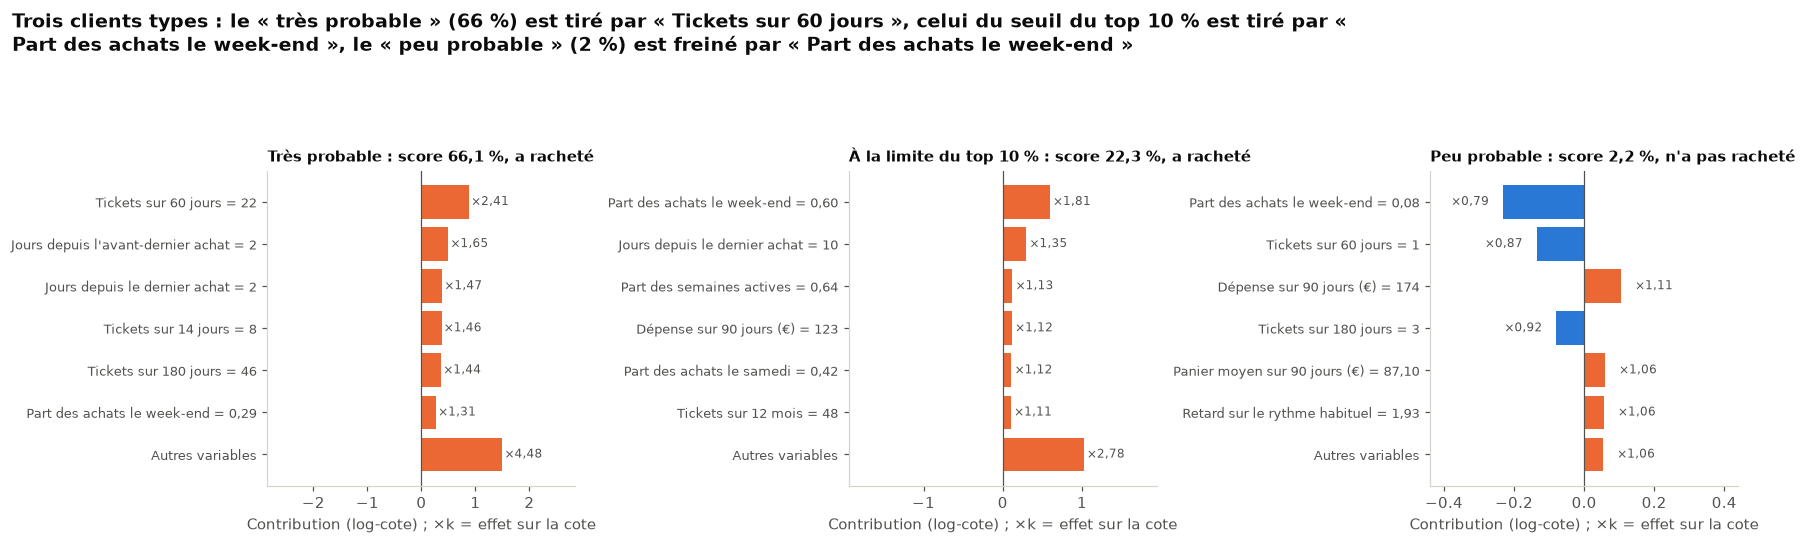

**Lecture.** Chaque barre est la contribution d'une variable à la cote de rachat du client par rapport au client moyen (base : 2,6 %) ; « ×1,8 » = elle multiplie la cote par 1,8. Ces clients sont choisis **sur leur score** (centile 99, seuil du top 10 %, médiane), pas sur leur issue réelle ; leur rachat observé est indiqué dans le titre à titre d'illustration.

- **Très probable** (score 66,1 %, a racheté) : Tickets sur 60 jours = 22 (+0,88) ; Jours depuis l'avant-dernier achat = 2 (+0,50) ; Jours depuis le dernier achat = 2 (+0,39).
- **À la limite du top 10 %** (score 22,3 %, a racheté) : Part des achats le week-end = 0,60 (+0,59) ; Jours depuis le dernier achat = 10 (+0,30) ; Part des semaines actives = 0,64 (+0,12).
- **Peu probable** (score 2,2 %, n'a pas racheté) : Part des achats le week-end = 0,08 (−0,23) ; Tickets sur 60 jours = 1 (−0,13) ; Dépense sur 90 jours (€) = 174 (+0,11).

,id_client,score,a_rachete,top1,top2,top3
profil,,,,,,
Très probable,29212708,66.1%,1,"Tickets sur 60 jours = 22 (+0,88)","Jours depuis l'avant-dernier achat = 2 (+0,50)","Jours depuis le dernier achat = 2 (+0,39)"
À la limite du top 10 %,84964439,22.3%,1,"Part des achats le week-end = 0,60 (+0,59)","Jours depuis le dernier achat = 10 (+0,30)","Part des semaines actives = 0,64 (+0,12)"
Peu probable,10155540,2.2%,0,"Part des achats le week-end = 0,08 (−0,23)","Tickets sur 60 jours = 1 (−0,13)","Dépense sur 90 jours (€) = 174 (+0,11)"


In [14]:
# --- trois clients types : un très probable, un à la limite du top 10 %, un peu probable ---
sc_all = oof_s.to_numpy()
targets = {'Très probable': np.quantile(sc_all, .99), 'À la limite du top 10 %': thr, 'Peu probable': np.median(sc_all)}
chosen = {}
for lbl, tv in targets.items():
    j = int(np.argmin(np.abs(sc - tv)))
    chosen[lbl] = j

def fmt_val(k, v):
    if isinstance(v, str):
        return v
    if pd.isna(v):
        return 'n.d.'
    if abs(v) >= 100 or float(v).is_integer():
        return fr(v, 0)
    return fr(v, 2)

ex_rows, FIRST = [], {}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, (lbl, j) in zip(axs, chosen.items()):
    cid = S_own.index[j]; ct = S_own.iloc[j]
    top = ct.reindex(ct.abs().sort_values(ascending=False).index).head(6)
    rest = ct.sum() - top.sum()
    names = [f"{lab(k)} = {fmt_val(k, Xtr.loc[cid, k])}" for k in top.index] + ['Autres variables']
    vals = list(top.values) + [rest]
    ax.barh(range(len(vals))[::-1], vals, color=[c.ACCENT if v > 0 else c.BLUE for v in vals])
    ax.set_yticks(range(len(vals))[::-1]); ax.set_yticklabels(names, fontsize=8.3)
    for i, v in zip(range(len(vals))[::-1], vals):
        ax.text(v + (.04 if v >= 0 else -.04), i, f"×{fr(np.exp(v), 2)}", va='center', ha='left' if v >= 0 else 'right', fontsize=8, color=c.INK2)
    ax.axvline(0, color=c.INK2, lw=.8)
    xm = max(abs(v) for v in vals) * 1.9; ax.set_xlim(-xm, xm)
    ax.set_xlabel('Contribution (log-cote) ; ×k = effet sur la cote')
    ax.set_title(f"{lbl} : score {pc(sc[j])}, {'a racheté' if yv[IDX[j]] == 1 else 'n\'a pas racheté'}", loc='left', fontsize=9.8)
    for k in ct.index:
        pass
    FIRST[lbl] = (lab(top.index[0]), float(top.iloc[0]))
    ex_rows.append({'profil': lbl, 'id_client': int(cid), 'score': float(sc[j]), 'a_rachete': int(yv[IDX[j]]), 'base_prob': float(1 / (1 + np.exp(-BASE[j]))),
                    **{f'top{r + 1}': f"{lab(k)} = {fmt_val(k, Xtr.loc[cid, k])} ({sg(ct[k], 2)})" for r, k in enumerate(top.index)}, 'autres': float(rest)})
_f = list(FIRST.items()); _v = lambda t: 'tiré par' if t[1][1] > 0 else 'freiné par'
done(fig, '06_shap_clients', f"Trois clients types : le « très probable » ({pc(sc[chosen[_f[0][0]]], 0)}) est {_v(_f[0])} « {_f[0][1][0]} », celui du seuil du top 10 % est {_v(_f[1])} « {_f[1][1][0]} », le « peu probable » ({pc(sc[chosen[_f[2][0]]], 0)}) est {_v(_f[2])} « {_f[2][1][0]} »")
exdf = pd.DataFrame(ex_rows).set_index('profil'); c.save_result('06_client_examples', exdf)
md('**Lecture.** Chaque barre est la contribution d\'une variable à la cote de rachat du client par rapport au client moyen (base : ' + pc(1 / (1 + np.exp(-BASE.mean()))) + ') ; « ×1,8 » = elle multiplie la cote par 1,8. Ces clients sont choisis **sur leur score** (centile 99, seuil du top 10 %, médiane), pas sur leur issue réelle ; leur rachat observé est indiqué dans le titre à titre d\'illustration.\n\n' +
   '\n'.join(f"- **{p}** (score {pc(r['score'])}, {'a racheté' if r['a_rachete'] else 'n\'a pas racheté'}) : " + ' ; '.join(r[f'top{i}'] for i in (1, 2, 3)) + '.' for p, r in exdf.iterrows()))
display(exdf[['id_client', 'score', 'a_rachete', 'top1', 'top2', 'top3']].style.format({'score': '{:.1%}'}))

## 5. Profil du racheteur et du non-racheteur

Pour la direction marketing : à quoi ressemble, **avant** août, un client qui rachète en août 2020 ? Moyennes sur les 160 424 clients du train, selon la cible réelle (`repurchase`), avec en regard la moyenne des 10 % de clients que le modèle cible. Ce sont des **moyennes descriptives**, non conditionnelles : récence, fréquence et dépense se recouvrent largement. *Lien avec le cours : interprétation par profils (slides 31-47, appliquée ici à la cible).*

,libellé,moyenne Racheteurs,moyenne Non-racheteurs,rapport racheteurs / non,moyenne Top 10 % du score,médiane Racheteurs,médiane Non-racheteurs
variable,,,,,,,
recency_days,Jours depuis le dernier achat,14.60,107.07,0.14,3.73,4.00,56.00
n_tickets_60,Tickets sur les 60 derniers jours,11.40,2.37,4.80,14.93,8.00,1.00
n_tickets_180,Tickets sur les 180 derniers jours,30.19,6.95,4.34,39.21,22.00,2.00
active_weeks_share,Part des semaines actives depuis le 1er achat,0.62,0.25,2.43,0.76,0.65,0.16
interval_mean_days,Intervalle moyen entre deux achats (jours),11.87,30.13,0.39,5.59,6.58,17.00
spend_90,Dépense sur 90 jours (€),724.42,187.02,3.87,938.37,500.51,28.52
basket_mean_all,Panier moyen sur 12 mois (€),50.20,51.78,0.97,48.07,41.38,39.17
share_weekend,Part des achats le week-end,0.32,0.25,1.26,0.34,0.28,0.20
discount_rate_all,Taux de remise moyen,0.05,0.04,1.33,0.06,0.04,0.02


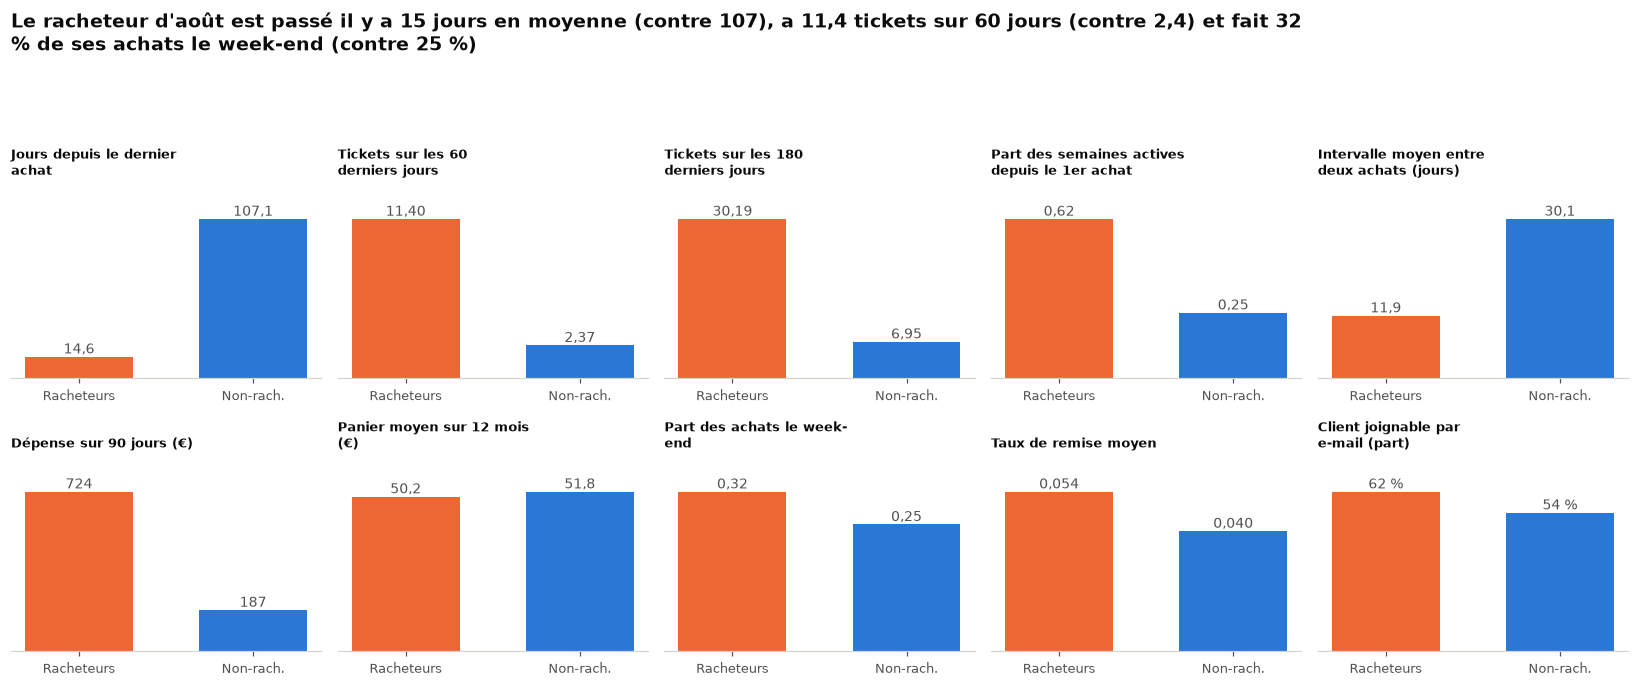


**Le portrait, en langage marketing.**
- **Le racheteur est un habitué actif** : il est venu il y a 15 jours en moyenne (médiane 4) contre 107 pour les autres (médiane 56) ; il fait **4,3 fois plus de tickets** sur 6 mois et vient tous les 12 jours en moyenne contre 30.
- **Il dépense plus, mais pas parce que son panier est plus gros** : sa dépense sur 90 jours est 3,9 fois plus élevée, son panier moyen seulement 3 % plus bas : c'est la fréquence qui fait la valeur, pas le montant.
- **Il vient plus souvent le week-end** (32 % de ses tickets contre 25 %) : c'est le point à manier avec précaution (section 6).
- **Joignabilité** : 62 % des racheteurs ont un e-mail, contre 54 % des non-racheteurs ; le top 10 % du modèle en compte 64 %.
- Le profil moyen du **top 10 % du score** ressemble à celui des racheteurs mais en plus marqué (récence moyenne 4 jours) : le modèle cible des « sur-habitués », dont beaucoup auraient acheté sans e-mail (question de l'**incrémentalité**, traitée par test A/B au notebook 07).


In [15]:
PROF = [('recency_days', 'Jours depuis le dernier achat', 1), ('n_tickets_60', 'Tickets sur les 60 derniers jours', 2), ('n_tickets_180', 'Tickets sur les 180 derniers jours', 2),
        ('active_weeks_share', 'Part des semaines actives depuis le 1er achat', 2), ('interval_mean_days', 'Intervalle moyen entre deux achats (jours)', 1),
        ('spend_90', 'Dépense sur 90 jours (€)', 0), ('basket_mean_all', 'Panier moyen sur 12 mois (€)', 1), ('share_weekend', "Part des achats le week-end", 2),
        ('discount_rate_all', 'Taux de remise moyen', 3), ('has_email', 'Client joignable par e-mail (part)', 2)]
grp = {'Racheteurs': yv == 1, 'Non-racheteurs': yv == 0, 'Top 10 % du score': top_mask}
rows = []
for k, lbl, nd in PROF:
    xv = Xtr[k].astype(float)
    r = {'variable': k, 'libellé': lbl}
    for g, m in grp.items():
        r[f'moyenne {g}'] = xv[m].mean(); r[f'médiane {g}'] = xv[m].median()
    r['rapport racheteurs / non'] = r['moyenne Racheteurs'] / r['moyenne Non-racheteurs']
    rows.append(r)
prof = pd.DataFrame(rows).set_index('variable')
c.save_result('06_profil_racheteur', prof)
display(prof[['libellé', 'moyenne Racheteurs', 'moyenne Non-racheteurs', 'rapport racheteurs / non', 'moyenne Top 10 % du score', 'médiane Racheteurs', 'médiane Non-racheteurs']].style.format(
    {k: '{:,.2f}' for k in prof.columns if k != 'libellé'}))

fig, axs = plt.subplots(2, 5, figsize=(15, 6.2))
for ax, (k, lbl, nd) in zip(axs.ravel(), PROF):
    a, b = prof.loc[k, 'moyenne Racheteurs'], prof.loc[k, 'moyenne Non-racheteurs']
    ax.bar([0, 1], [a, b], color=[c.ACCENT, c.BLUE], width=.62)
    for i, v in enumerate([a, b]):
        ax.text(i, v, (fr(v * 100, 0) + ' %') if k in ('has_email',) else fr(v, nd), ha='center', va='bottom', fontsize=9, color=c.INK2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Racheteurs', 'Non-rach.'], fontsize=8.5)
    ax.set_title(textwrap.fill(lbl, 26), loc='left', fontsize=8.8); ax.set_ylim(0, max(a, b) * 1.22); ax.set_yticks([])
    ax.spines['left'].set_visible(False)
pr = prof
done(fig, '06_profil_racheteur', f"Le racheteur d'août est passé il y a {fr(pr.loc['recency_days', 'moyenne Racheteurs'], 0)} jours en moyenne (contre {fr(pr.loc['recency_days', 'moyenne Non-racheteurs'], 0)}), a {fr(pr.loc['n_tickets_60', 'moyenne Racheteurs'], 1)} tickets sur 60 jours (contre {fr(pr.loc['n_tickets_60', 'moyenne Non-racheteurs'], 1)}) et fait {pc(pr.loc['share_weekend', 'moyenne Racheteurs'], 0)} de ses achats le week-end (contre {pc(pr.loc['share_weekend', 'moyenne Non-racheteurs'], 0)})")
md(f'''
**Le portrait, en langage marketing.**
- **Le racheteur est un habitué actif** : il est venu il y a {fr(pr.loc['recency_days', 'moyenne Racheteurs'], 0)} jours en moyenne (médiane {fr(pr.loc['recency_days', 'médiane Racheteurs'], 0)}) contre {fr(pr.loc['recency_days', 'moyenne Non-racheteurs'], 0)} pour les autres (médiane {fr(pr.loc['recency_days', 'médiane Non-racheteurs'], 0)}) ; il fait **{fr(pr.loc['n_tickets_180', 'rapport racheteurs / non'], 1)} fois plus de tickets** sur 6 mois et vient tous les {fr(pr.loc['interval_mean_days', 'moyenne Racheteurs'], 0)} jours en moyenne contre {fr(pr.loc['interval_mean_days', 'moyenne Non-racheteurs'], 0)}.
- **Il dépense plus, mais pas parce que son panier est plus gros** : sa dépense sur 90 jours est {fr(pr.loc['spend_90', 'rapport racheteurs / non'], 1)} fois plus élevée, son panier moyen seulement {fr(abs(pr.loc['basket_mean_all', 'rapport racheteurs / non'] - 1) * 100, 0)} % {'plus haut' if pr.loc['basket_mean_all', 'rapport racheteurs / non'] > 1 else 'plus bas'} : c'est la fréquence qui fait la valeur, pas le montant.
- **Il vient plus souvent le week-end** ({pc(pr.loc['share_weekend', 'moyenne Racheteurs'], 0)} de ses tickets contre {pc(pr.loc['share_weekend', 'moyenne Non-racheteurs'], 0)}) : c'est le point à manier avec précaution (section 6).
- **Joignabilité** : {pc(pr.loc['has_email', 'moyenne Racheteurs'], 0)} des racheteurs ont un e-mail, contre {pc(pr.loc['has_email', 'moyenne Non-racheteurs'], 0)} des non-racheteurs ; le top 10 % du modèle en compte {pc(pr.loc['has_email', 'moyenne Top 10 % du score'], 0)}.
- Le profil moyen du **top 10 % du score** ressemble à celui des racheteurs mais en plus marqué (récence moyenne {fr(pr.loc['recency_days', 'moyenne Top 10 % du score'], 0)} jours) : le modèle cible des « sur-habitués », dont beaucoup auraient acheté sans e-mail (question de l'**incrémentalité**, traitée par test A/B au notebook 07).
''')
KEY.update({'profil_recence_racheteur': float(pr.loc['recency_days', 'moyenne Racheteurs']), 'profil_recence_non': float(pr.loc['recency_days', 'moyenne Non-racheteurs']),
            'profil_tickets60_racheteur': float(pr.loc['n_tickets_60', 'moyenne Racheteurs']), 'profil_tickets60_non': float(pr.loc['n_tickets_60', 'moyenne Non-racheteurs']),
            'profil_weekend_racheteur': float(pr.loc['share_weekend', 'moyenne Racheteurs']), 'profil_weekend_non': float(pr.loc['share_weekend', 'moyenne Non-racheteurs'])})

## 6. Robustesse, et le risque de `share_weekend`

**D'abord la stabilité statistique** : AUC par pli et écart-type, intervalle de confiance par rééchantillonnage des clients. **Ensuite un risque de fond**, soulevé par le notebook 04 : `share_weekend` domine l'importance par permutation, alors que **août 2020 commence un samedi** et compte 10 jours de week-end. Avec un seul mois cible, on ne peut pas séparer un vrai trait de comportement (« client des week-ends ») d'un effet de calendrier propre à ce mois. On **n'essaie pas de le résoudre ici** ; on mesure ce qu'on peut mesurer et on dit ce qu'on ne sait pas.

*Lien avec le cours : stabilité entre plis (slides 66-73) ; saisonnalité et fenêtre de calcul de la cible (slides 50-52, 82-84).*

In [16]:
# --- stabilité statistique ---
rs = np.random.RandomState(c.SEED)
sc_np = oof_s.to_numpy()
boot = np.array([roc_auc_score(yv[i], sc_np[i]) for i in (rs.randint(0, n, n) for _ in range(N_BOOT))])
ci = np.percentile(boot, [2.5, 97.5])
rob = pd.DataFrame({'auc_final': fold_auc_f, 'auc_lasso': fold_auc['logreg_lasso'], 'auc_recence': fold_auc['recency_rule']}, index=pd.Index(range(c.N_FOLDS), name='pli'))
rob.loc['moyenne'] = rob.iloc[:c.N_FOLDS].mean(); rob.loc['écart-type'] = rob.iloc[:c.N_FOLDS].std(ddof=0)
c.save_result('06_robustesse_plis', rob)
display(rob.style.format('{:.4f}', na_rep='-'))
md(f'''
- AUC par pli du modèle final : de **{a4(fold_auc_f.min())}** à **{a4(fold_auc_f.max())}**, moyenne {a4(fold_auc_f.mean())}, écart-type **{a4(fold_auc_f.std())}**. Le modèle final devance le Lasso dans {int((fold_auc_f > fold_auc['logreg_lasso']).sum())} plis sur 5 et la récence seule dans {int((fold_auc_f > fold_auc['recency_rule']).sum())} sur 5.
- Intervalle de confiance à 95 % de l'AUC hors-échantillon (bootstrap sur les clients, {N_BOOT} tirages) : **[{a4(ci[0])} ; {a4(ci[1])}]**. Ordre de grandeur de ce qu'on peut attendre sur le test Kaggle (40 106 clients, donc un intervalle plus large : environ ±{fr(1.96 * boot.std() * np.sqrt(N_TR / len(Xte)), 3)}), **si** le mois et la population sont les mêmes.
- **Optimisme résiduel** : les hyperparamètres ont été réglés sur un sous-échantillon tiré dans les mêmes plis (notebook 04) ; l'AUC hors-échantillon est donc légèrement optimiste, de l'ordre du bruit entre plis ou moins.
''')
KEY.update({'auc_fold_min': float(fold_auc_f.min()), 'auc_fold_max': float(fold_auc_f.max()), 'auc_fold_std': float(fold_auc_f.std()), 'auc_boot_ci95': [float(ci[0]), float(ci[1])]})

,auc_final,auc_lasso,auc_recence
pli,,,
0,0.8797,0.8724,0.8201
1,0.8767,0.8700,0.8202
2,0.8790,0.8706,0.8170
3,0.8757,0.8685,0.8117
4,0.8818,0.8754,0.8213
moyenne,0.8786,0.8714,0.8180
écart-type,0.0022,0.0024,0.0035



- AUC par pli du modèle final : de **0,8757** à **0,8818**, moyenne 0,8786, écart-type **0,0022**. Le modèle final devance le Lasso dans 5 plis sur 5 et la récence seule dans 5 sur 5.
- Intervalle de confiance à 95 % de l'AUC hors-échantillon (bootstrap sur les clients, 200 tirages) : **[0,8759 ; 0,8816]**. Ordre de grandeur de ce qu'on peut attendre sur le test Kaggle (40 106 clients, donc un intervalle plus large : environ ±0,006), **si** le mois et la population sont les mêmes.
- **Optimisme résiduel** : les hyperparamètres ont été réglés sur un sous-échantillon tiré dans les mêmes plis (notebook 04) ; l'AUC hors-échantillon est donc légèrement optimiste, de l'ordre du bruit entre plis ou moins.


,tous,au moins 10 tickets,effectif tous,effectif ≥ 10 tickets
share_weekend,,,,
0 %,1.0%,2.1%,"46,441","3,847"
0-15 %,6.6%,7.4%,"18,240","14,970"
15-30 %,12.9%,16.0%,"40,317","30,967"
30-45 %,13.0%,18.5%,"24,818","16,180"
45-60 %,8.6%,18.6%,"14,661","5,853"
60-100 %,6.5%,26.8%,"15,937","3,060"


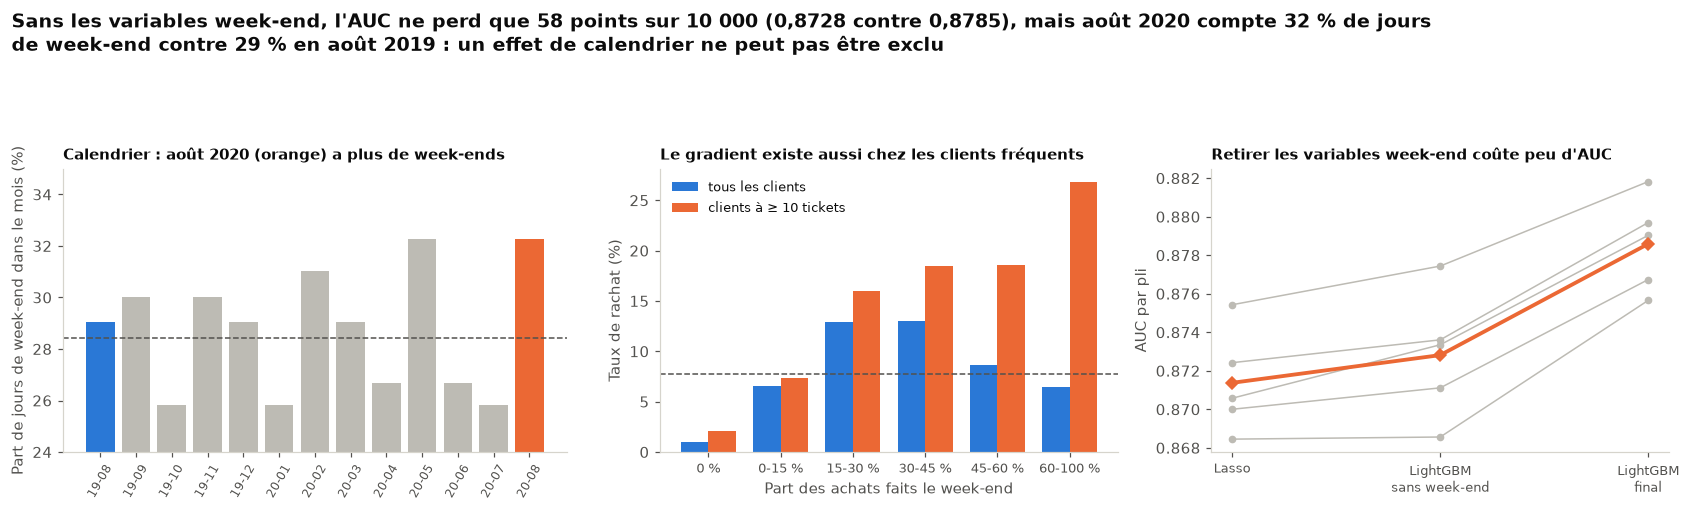

In [17]:
# --- diagnostic 1 : le calendrier de chaque mois ---
months = pd.period_range('2019-08', '2020-08', freq='M')
cal = []
for p in months:
    d = pd.date_range(p.start_time, p.end_time.normalize(), freq='D')
    cal.append({'mois': str(p), 'jours': len(d), 'jours_week_end': int((d.dayofweek >= 5).sum()), 'part_week_end': float((d.dayofweek >= 5).mean()), 'premier_jour': d[0].day_name(),
                'samedis': int((d.dayofweek == 5).sum())})
cal = pd.DataFrame(cal).set_index('mois')
we_aug20, we_aug19 = cal.loc['2020-08', 'part_week_end'], cal.loc['2019-08', 'part_week_end']
we_obs = cal.loc['2019-08':'2020-07', 'part_week_end']
c.save_result('06_calendrier_mois', cal)

# --- diagnostic 2 : taux de rachat selon la part d'achats le week-end (tous les clients, puis clients fréquents seulement) ---
bins = [-0.001, 0.0, 0.15, 0.30, 0.45, 0.60, 1.0]
labs_b = ['0 %', '0-15 %', '15-30 %', '30-45 %', '45-60 %', '60-100 %']
sw_ = Xtr['share_weekend']
tab_we = pd.DataFrame({'tous': pd.Series(yv, index=Xtr.index).groupby(pd.cut(sw_, bins, labels=labs_b)).mean(),
                       'au moins 10 tickets': pd.Series(yv, index=Xtr.index)[Xtr['n_tickets_all'] >= 10].groupby(pd.cut(sw_[Xtr['n_tickets_all'] >= 10], bins, labels=labs_b)).mean(),
                       'effectif tous': pd.cut(sw_, bins, labels=labs_b).value_counts().reindex(labs_b),
                       'effectif ≥ 10 tickets': pd.cut(sw_[Xtr['n_tickets_all'] >= 10], bins, labels=labs_b).value_counts().reindex(labs_b)})
c.save_result('06_rachat_selon_weekend', tab_we)
display(tab_we.style.format({'tous': '{:.1%}', 'au moins 10 tickets': '{:.1%}', 'effectif tous': '{:,.0f}', 'effectif ≥ 10 tickets': '{:,.0f}'}))

# --- diagnostic 3 : même modèle sans les deux variables de jour de semaine (5 plis, mêmes hyperparamètres) ---
drop = ['share_weekend', 'share_saturday']
keep_idx = [i for i, e in enumerate(ENC_COLS) if e not in drop]
oof_nw, te_nw, _, _ = fit_cv(keep_idx)
rep_nw = c.cv_report(y, oof_nw, folds)
fold_auc_nw = np.array([roc_auc_score(yv[fold == k], oof_nw.to_numpy()[fold == k]) for k in range(c.N_FOLDS)])
d_nw = fold_auc_f - fold_auc_nw
rho_te = spearmanr(te_s.to_numpy(), te_nw.reindex(te_s.index).to_numpy())[0]
diag = {'auc_final': rep_f['auc'], 'auc_sans_weekend': rep_nw['auc'], 'perte_auc': rep_f['auc'] - rep_nw['auc'], 'perte_auc_par_pli': d_nw.tolist(),
        'rappel_top10_final': rep_f['recall_top10'], 'rappel_top10_sans_weekend': rep_nw['recall_top10'],
        'lift_top10_sans_weekend': rep_nw['lift_top10'], 'auc_lasso': rep['logreg_lasso']['auc'],
        'part_weekend_aout_2020': we_aug20, 'part_weekend_aout_2019': we_aug19, 'part_weekend_moyenne_12_mois': float(we_obs.mean()),
        'rho_scores_test_final_vs_sans_weekend': float(rho_te)}
c.save_result('06_diagnostic_calendrier', diag)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw={'width_ratios': [1.1, 1.0, 1.0]})
ax = axs[0]
colm = [c.ACCENT if m == '2020-08' else (c.BLUE if m == '2019-08' else c.GREY) for m in cal.index]
ax.bar(range(len(cal)), cal['part_week_end'] * 100, color=colm)
ax.set_xticks(range(len(cal))); ax.set_xticklabels([m[2:] for m in cal.index], rotation=60, fontsize=8)
ax.axhline(we_obs.mean() * 100, color=c.INK2, lw=1, ls='--'); ax.set_ylim(24, 35); ax.set_ylabel('Part de jours de week-end dans le mois (%)')
ax.set_title('Calendrier : août 2020 (orange) a plus de week-ends', loc='left', fontsize=9.5)
ax = axs[1]
w = .38; xs = np.arange(len(labs_b))
ax.bar(xs - w / 2, tab_we['tous'] * 100, w, color=c.BLUE, label='tous les clients'); ax.bar(xs + w / 2, tab_we['au moins 10 tickets'] * 100, w, color=c.ACCENT, label='clients à ≥ 10 tickets')
ax.axhline(BASE_RATE * 100, color=c.INK2, lw=1, ls='--')
ax.set_xticks(xs); ax.set_xticklabels(labs_b, fontsize=8.5); ax.set_xlabel("Part des achats faits le week-end"); ax.set_ylabel('Taux de rachat (%)'); ax.legend(frameon=False, fontsize=8.5)
ax.set_title('Le gradient existe aussi chez les clients fréquents', loc='left', fontsize=9.5)
ax = axs[2]
for k in range(c.N_FOLDS):
    ax.plot([0, 1, 2], [fold_auc['logreg_lasso'][k], fold_auc_nw[k], fold_auc_f[k]], color=c.GREY, lw=1, marker='o', ms=4)
ax.plot([0, 1, 2], [fold_auc['logreg_lasso'].mean(), fold_auc_nw.mean(), fold_auc_f.mean()], color=c.ACCENT, lw=2.5, marker='D')
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['Lasso', 'LightGBM\nsans week-end', 'LightGBM\nfinal'], fontsize=8.5); ax.set_ylabel('AUC par pli')
ax.set_title('Retirer les variables week-end coûte peu d\'AUC', loc='left', fontsize=9.5)
done(fig, '06_risque_calendrier', f"Sans les variables week-end, l'AUC ne perd que {fr(diag['perte_auc'] * 1e4, 0)} points sur 10 000 ({a4(rep_nw['auc'])} contre {a4(rep_f['auc'])}), mais août 2020 compte {pc(we_aug20, 0)} de jours de week-end contre {pc(we_aug19, 0)} en août 2019 : un effet de calendrier ne peut pas être exclu")

In [18]:
JOUR = {'Monday': 'lundi', 'Tuesday': 'mardi', 'Wednesday': 'mercredi', 'Thursday': 'jeudi', 'Friday': 'vendredi', 'Saturday': 'samedi', 'Sunday': 'dimanche'}
a15 = JOUR[pd.Timestamp('2020-08-15').day_name()]; a15_19 = JOUR[pd.Timestamp('2019-08-15').day_name()]
prem = JOUR[cal.loc['2020-08', 'premier_jour']]
rate_lo, rate_hi = tab_we['au moins 10 tickets'].iloc[1], tab_we['au moins 10 tickets'].iloc[-1]
md(f'''
**Ce que montrent les diagnostics.**

1. **Le calendrier d'août 2020 est atypique.** Il commence un {prem}, compte {cal.loc['2020-08', 'jours_week_end']} jours de week-end sur {cal.loc['2020-08', 'jours']} ({pc(we_aug20)}) dont {cal.loc['2020-08', 'samedis']} samedis (le gros jour de courses), et son 15 août tombe un {a15} (en 2019 : un {a15_19}). Août 2019 en comptait {cal.loc['2019-08', 'jours_week_end']} ({pc(we_aug19)}) ; la moyenne des 12 mois observés est de {pc(we_obs.mean())}.
2. **Le gradient existe dans les données, y compris chez les clients fréquents.** Chez les clients à au moins 10 tickets, le taux de rachat passe de {pc(rate_lo)} (0-15 % d'achats le week-end) à {pc(rate_hi)} (plus de 60 %) : ce n'est pas un simple artefact des clients à 1 ou 2 tickets, dont la part de week-end vaut mécaniquement 0 ou 1 (c'est d'ailleurs ce qui rend la courbe « tous clients » non monotone au-delà de 45 %). Le gradient n'est toutefois pas ajusté sur la récence ni la fréquence : il peut en partie les refléter.
3. **Le coût en AUC est limité.** Sans `share_weekend` ni `share_saturday`, l'AUC passe de {a4(rep_f['auc'])} à {a4(rep_nw['auc'])} (perte de {fr(diag['perte_auc'], 4)}, positive dans {int((d_nw > 0).sum())} plis sur 5), et le rappel du top 10 % de {pc(rep_f['recall_top10'])} à {pc(rep_nw['recall_top10'])}. Le modèle sans ces variables ({a4(rep_nw['auc'])}) reste {'au-dessus' if rep_nw['auc'] > rep['logreg_lasso']['auc'] else 'au niveau'} du Lasso ({a4(rep['logreg_lasso']['auc'])}). Corrélation de rang des scores du test entre les deux versions : {fr(rho_te, 3)}.
4. **Le Lasso place la même variable en tête** (OR par écart-type de {fr(cmp_.loc['share_weekend', 'or_lasso'], 2)}) : le signal n'est pas propre au boosting.

**Ce que l'on ne sait pas (et que les données ne permettent pas de trancher).** Deux explications sont compatibles avec ce que l'on observe :
- *Un vrai trait de comportement* : par exemple, les clients qui font leurs courses du foyer le week-end seraient plus engagés et rachèteraient plus souvent quel que soit le mois (hypothèse, non testée ici).
- *Un effet de calendrier* : en août 2020, un client « du week-end » dispose de plus d'occasions d'acheter (10 jours de week-end, mois ouvert un samedi, jour férié un samedi). Le modèle, entraîné sur **ce seul mois**, ne peut pas le distinguer de la première explication.

**Conséquences.** (i) Pour la **soumission Kaggle**, le test est tiré dans la même population et porte sur **le même mois** : si l'effet est un effet de calendrier, il joue aussi sur le test, donc il ne nuit pas à l'AUC attendue. (ii) Pour un **déploiement mensuel réel** (septembre, octobre…), le poids de `share_weekend` serait probablement **surestimé** si c'est un effet de calendrier : le classement resterait utile (le reste du modèle tient seul à {a4(rep_nw['auc'])}) mais moins bon, avec un risque de sur-cibler les clients du week-end. (iii) Piste pour la phase d'optimisation : construire le même score pour plusieurs mois-cibles passés et regarder si le gradient du week-end y est stable (interdit dans cette première passe) ; à défaut, garder en parallèle la version sans variables de jour de semaine comme garde-fou.
''')


**Ce que montrent les diagnostics.**

1. **Le calendrier d'août 2020 est atypique.** Il commence un samedi, compte 10 jours de week-end sur 31 (32,3 %) dont 5 samedis (le gros jour de courses), et son 15 août tombe un samedi (en 2019 : un jeudi). Août 2019 en comptait 9 (29,0 %) ; la moyenne des 12 mois observés est de 28,4 %.
2. **Le gradient existe dans les données, y compris chez les clients fréquents.** Chez les clients à au moins 10 tickets, le taux de rachat passe de 7,4 % (0-15 % d'achats le week-end) à 26,8 % (plus de 60 %) : ce n'est pas un simple artefact des clients à 1 ou 2 tickets, dont la part de week-end vaut mécaniquement 0 ou 1 (c'est d'ailleurs ce qui rend la courbe « tous clients » non monotone au-delà de 45 %). Le gradient n'est toutefois pas ajusté sur la récence ni la fréquence : il peut en partie les refléter.
3. **Le coût en AUC est limité.** Sans `share_weekend` ni `share_saturday`, l'AUC passe de 0,8785 à 0,8728 (perte de 0,0058, positive dans 5 plis sur 5), et le rappel du top 10 % de 52,6 % à 50,8 %. Le modèle sans ces variables (0,8728) reste au-dessus du Lasso (0,8714). Corrélation de rang des scores du test entre les deux versions : 0,984.
4. **Le Lasso place la même variable en tête** (OR par écart-type de 1,76) : le signal n'est pas propre au boosting.

**Ce que l'on ne sait pas (et que les données ne permettent pas de trancher).** Deux explications sont compatibles avec ce que l'on observe :
- *Un vrai trait de comportement* : par exemple, les clients qui font leurs courses du foyer le week-end seraient plus engagés et rachèteraient plus souvent quel que soit le mois (hypothèse, non testée ici).
- *Un effet de calendrier* : en août 2020, un client « du week-end » dispose de plus d'occasions d'acheter (10 jours de week-end, mois ouvert un samedi, jour férié un samedi). Le modèle, entraîné sur **ce seul mois**, ne peut pas le distinguer de la première explication.

**Conséquences.** (i) Pour la **soumission Kaggle**, le test est tiré dans la même population et porte sur **le même mois** : si l'effet est un effet de calendrier, il joue aussi sur le test, donc il ne nuit pas à l'AUC attendue. (ii) Pour un **déploiement mensuel réel** (septembre, octobre…), le poids de `share_weekend` serait probablement **surestimé** si c'est un effet de calendrier : le classement resterait utile (le reste du modèle tient seul à 0,8728) mais moins bon, avec un risque de sur-cibler les clients du week-end. (iii) Piste pour la phase d'optimisation : construire le même score pour plusieurs mois-cibles passés et regarder si le gradient du week-end y est stable (interdit dans cette première passe) ; à défaut, garder en parallèle la version sans variables de jour de semaine comme garde-fou.


## 7. Limites et pistes d'amélioration

- **Un seul mois cible, un seul découpage.** Plis aléatoires, une seule date de coupure (1er août 2020) : on ne mesure ni la dérive dans le temps ni la stabilité d'un mois à l'autre. Le risque `share_weekend` (section 6) en est la conséquence directe.
- **AUC légèrement optimiste.** Réglage des hyperparamètres sur un sous-échantillon pris dans les mêmes plis ; pas de jeu de validation entièrement isolé. L'écart avec le futur score du test Kaggle sera au moins de l'ordre du bruit entre plis.
- **Cible plus étroite que « acheter dans le mois ».** Les probabilités ne sont pas des taux mensuels ; seul le classement et les taux par décile sont exploitables pour le chiffrage.
- **Score prédictif ≠ effet incrémental.** Le modèle repère les clients qui rachèteront de toute façon (sur-habitués) ; il ne dit pas qui **réagira** à l'e-mail. Seul un test A/B avec groupe témoin le mesure (notebook 07). 45 % de la base n'a pas d'e-mail : le top 10 % réellement joignable est plus petit.
- **Profil d'identité.** Civilité, domaine d'e-mail et département ne coûtent que très peu d'AUC en les retirant (section 1) mais sont des proxys possibles d'âge et de territoire : à retirer ou à auditer avant un usage opérationnel.
- **SHAP décrit le modèle, pas le monde.** Les contributions sont des associations ; corrélations fortes entre variables de récence et de fréquence (SHAP les répartit de façon conventionnelle) ; les odds ratios du notebook 03 ne portent que sur 49 variables publiées.
- **Pistes.** Plusieurs mois-cibles (multi-coupures) pour tester le calendrier ; graines multiples et validation imbriquée ; catégories natives de LightGBM ; nouvelles fenêtres temporelles ; open data (INSEE, calendrier, météo) ; suivi de la dérive et ré-entraînement mensuel (slide 76).

In [19]:
# --- sorties : JSON des chiffres clés et résumé ---
best_json.update({'auc_sans_variables_weekend': rep_nw['auc'], 'ic95_auc_bootstrap': [float(ci[0]), float(ci[1])],
                  'hyperparametres': P, 'n_colonnes': int(A_tr.shape[1]), 'n_jobs': N_JOBS})
c.save_result('06_best_model', best_json)
c.save_result('best_model', best_json)          # nom prévu par le brief commun (carte des notebooks)
KEY.update({'precision_top10_lasso': rep['logreg_lasso']['precision_top10'], 'recall_top10_lasso': rep['logreg_lasso']['recall_top10'],
            'recall_top10_recence': rep['recency_rule']['recall_top10'], 'auc_sans_weekend': rep_nw['auc'], 'perte_auc_weekend': diag['perte_auc'],
            'decile1_taux_rachat': float(dt.loc[1, 'taux_rachat'])})
c.save_result('06_key_numbers', KEY)

L = []
L.append('# Résumé du notebook 06 : modèle final, évaluation business et interprétation')
L.append('')
L.append('## Chiffres clés (train, 5 plis communs, hors-échantillon ; top 10 % = les 10 % de clients au meilleur score)')
L.append(f"- **Modèle final : `lgbm_tuned`** (LightGBM réglé, hyperparamètres de `results/04_best_params.json`, {A_tr.shape[1]} colonnes). Ré-entraînement fidèle : AUC {a4(rep_f['auc'])} (écart avec le notebook 04 : {gap_auc:.0e}) ; AUC par pli {a4(fold_auc_f.min())} à {a4(fold_auc_f.max())}, écart-type {a4(fold_auc_f.std())} ; IC 95 % bootstrap [{a4(ci[0])} ; {a4(ci[1])}].")
L.append(f"- Référence interprétable : `logreg_lasso`, AUC {a4(rep['logreg_lasso']['auc'])} ; le modèle final gagne {d_lasso[2]}/5 plis ({sg(d_lasso[0])} d'AUC). Contre XGBoost réglé ({sg(d_xgb[0])}) la différence est dans le bruit. Récence seule : AUC {a4(rep['recency_rule']['auc'])}.")
L.append(f"- **Top 10 % ({nf(k10)} clients)** : précision {pc(TP / k10)}, rappel {pc(TP / yv.sum())}, lift {fr(TP / k10 / BASE_RATE, 2)} (Lasso : {pc(rep['logreg_lasso']['precision_top10'])} / {pc(rep['logreg_lasso']['recall_top10'])} ; récence : {pc(rep['recency_rule']['precision_top10'])} / {pc(rep['recency_rule']['recall_top10'])}). Taux de rachat du 1er décile {pc(dt.loc[1, 'taux_rachat'])}, du dernier {pc(dt.loc[10, 'taux_rachat'])} (base {pc(BASE_RATE)}).")
L.append(f"- Calibration : score moyen = {fr(ratio, 2)} × taux réel, pente {fr(slope, 2)}, écart par décile {fr(ece * 100, 2)} pt ; on ne s'intéresse qu'au classement (cible plus étroite que « acheter dans le mois »).")
L.append(f"- Parmi le top 10 %, {pc(1 - share_top_mail, 0)} n'ont pas d'e-mail (injoignables par ce canal).")
L.append(f"- SHAP ({nf(len(IDX))} clients, explications hors-pli, additivité vérifiée à {add_err:.0e}) : 5 premières variables = " + ', '.join(f'`{k}`' for k in imp.index[:5]) + f", {pc(share_imp.head(5).sum(), 0)} de l'importance. Accord avec les odds ratios du notebook 03 : même sens sur {KEY['shap_or_same_sign']} variables comparables, corrélation de rang {fr(rho_rank, 2)}.")
L.append(f"- Profil du racheteur : dernier achat il y a {fr(pr.loc['recency_days', 'moyenne Racheteurs'], 0)} j (autres : {fr(pr.loc['recency_days', 'moyenne Non-racheteurs'], 0)} j), {fr(pr.loc['n_tickets_60', 'moyenne Racheteurs'], 1)} tickets sur 60 j (autres : {fr(pr.loc['n_tickets_60', 'moyenne Non-racheteurs'], 1)}), {pc(pr.loc['share_weekend', 'moyenne Racheteurs'], 0)} d'achats le week-end (autres : {pc(pr.loc['share_weekend', 'moyenne Non-racheteurs'], 0)}).")
L.append(f"- Risque calendrier : sans `share_weekend` et `share_saturday`, AUC {a4(rep_nw['auc'])} (perte {fr(diag['perte_auc'], 4)}) ; août 2020 : {pc(we_aug20)} de jours de week-end contre {pc(we_aug19)} en août 2019.")
L.append('')
L.append('## Fichiers produits')
L.append('- `submissions/06_final.csv` (non envoyé à Kaggle) ; prédictions `final_lgbm` ; `results/06_best_model.json` (copie : `results/best_model.json`), `06_model_selection.csv`, `06_deciles.csv`, `06_topk_metrics.csv`, `06_calibration.csv`, `06_shap_importance.csv`, `06_shap_dependance.csv`, `06_client_examples.csv`, `06_profil_racheteur.csv`, `06_robustesse_plis.csv`, `06_calendrier_mois.csv`, `06_rachat_selon_weekend.csv`, `06_diagnostic_calendrier.json`, `06_key_numbers.json`.')
L.append('')
L.append('## Figures (message)')
for k, v in FIG_MSG.items():
    L.append(f'- `figures/{k}.png` : {v}')
L.append('')
L.append('## Décisions méthodologiques')
L.append("- Modèle final = meilleur AUC hors-échantillon (LightGBM réglé), non pas par supériorité nette sur XGBoost mais par performance, vitesse et SHAP exact ; Lasso gardé comme référence lisible. Mêmes variables que le notebook 04 (profil d'identité conservé pour rester comparable).")
L.append("- Test = moyenne des 5 modèles de pli (pas de ré-ajustement) ; le test ne sert à aucune décision. SHAP : 2 000 clients par pli de validation, expliqués par le modèle du pli, one-hot additionné par variable.")
L.append('')
L.append('## Anomalies et limites')
L.append("- **`share_weekend` : risque d'effet de calendrier non tranché** (un seul mois cible ; août 2020 commence un samedi, 10 jours de week-end). Acceptable pour le test Kaggle (même mois), à ne pas extrapoler à un déploiement mensuel sans multi-coupures.")
L.append("- AUC légèrement optimiste (réglage sur les mêmes plis) ; un seul mois, plis aléatoires. Score prédictif ≠ effet incrémental (test A/B au notebook 07). Profil d'identité : proxy possible d'âge et de territoire.")
L.append("- Odds ratios du notebook 03 : 49 variables publiées seulement ; la comparaison SHAP / odds ratios ne porte que sur celles-ci.")
L.append('')
L.append('## Pistes')
L.append("- Multi-coupures et graines multiples pour mesurer le calendrier et la variance ; version sans variables de jour de semaine comme garde-fou ; catégories natives LightGBM ; open data ; suivi de dérive.")
assert len(L) <= 60, len(L)
(c.RES / '06_summary.md').write_text('\n'.join(L) + '\n', encoding='utf-8')
print(len(L), 'lignes écrites dans results/06_summary.md')

38 lignes écrites dans results/06_summary.md
